# CS6362 Assignment 2 · Paper 3: β-VAE Figure 7A/B reproduction

**Source restriction:** Written using only the provided Higgins et al. (ICLR 2017) PDF and the course assignment PDF. No author code, existing implementation, peer review, or third-party reproduction was consulted. **Default behavior: no dataset loading, download, or model training.**

**Goal:** Reproduce Figure 7A (β=4) and Figure 7B (β=1) on the full factorial 737,280-example binary 64×64 2D-shapes dataset, including *factor-response plots* and *decoded latent traversals*. All outputs are computed from trained checkpoints; no Figure 7 result is hard-coded.

## Paper settings vs documented choices

| Topic | Specified in Higgins et al. | This reproduction's explicit choice / uncertainty |
|---|---|---|
| Dataset | 737,280 binary 64×64 shapes; 3 identities, 6 scales, 40 rotations, 32 X and 32 Y positions | Expect locally supplied dSprites-compatible `.npz` with `imgs` and `latents_classes`. Factor columns interpreted as `[color, shape, scale, orientation, posX, posY]`, with first factor singleton. This storage schema/ordering is an assumption about the supplied dataset, **not** stated in the paper. Validated at load time. |
| Architecture | Input 4096; encoder FC 1200,1200 with ReLU; 10 Gaussian latents; decoder FC 1200,1200,1200,4096 with Tanh and Bernoulli output (Appendix Table 1, p.13) | Tanh between decoder FC layers, final logits passed to Bernoulli BCE; diagonal Gaussian posterior; PyTorch default Linear initialization. The exact placement of decoder Tanh isn't fully specified. |
| Objective | Eq. 4: reconstruction log-likelihood − β KL to N(0,I) | Minimize **sum of 4096 binary cross-entropies per image + β × sum of 10 latent KLs**, averaged over batch. No loss-term averaging per pixel (which would silently reweight β). |
| Optimizer | Adagrad learning rate 1e−2 | PyTorch `Adagrad(lr=0.01)` defaults for other parameters. No scheduler or weight decay; the paper does not specify additional optimizer defaults. |
| Training | β=1 versus β=4; unsupervised | Batch size **128**; full-training cap **100 epochs**; seeds **(0,1,2)** per β; no early stopping by default. All are **choices**, not published settings. The paper's Figure 6 quantitative study used 10 replicas, **not evidence that Fig. 7 itself used exactly 10**. |
| Latent ordering | Figure 7 caption: columns ordered by learned Gaussian variance, shown last row | Sort by full-dataset mean posterior variance `E_x[exp(log σ²(x))]` **ascending**; show the five lowest-variance latents plus the highest-variance latent for comparison, as in Fig. 7. Save statistics for **all ten** coordinates. The aggregation is a chosen operational definition. |
| Factor responses | Position: average over shapes, rotations and scales; scale and rotation: curves by shape, marginalized over remaining factors | Compute empirical factorial averages from all **737,280** examples in full mode. Color convention: square red, oval green, heart blue. Also export supplementary **shape means**. |
| Traversal | Fig. 7 caption: one latent varied within ±3 prior SD while remaining 9/10 fixed to values inferred on one image | Five ordered values **[+3,+1.5,0,−1.5,−3]**; other coordinates fixed to deterministic encoder posterior means of one explicitly recorded reference image: oval, middle scale, zero rotation, centered position. Absolute prior coordinates, not `μ(seed) ±3`. The exact paper seed and number of steps are unspecified. |
| Train split | Paper describes a complete Cartesian-product dataset; Fig.7 doesn't specify a held-out split | Full dataset is used for training and factor responses, with **no train/test split** introduced. Training loss and reconstruction diagnostics are not claimed as held-out evidence. |

**Paper citations:** Eq. 4, p.5; §4.2, pp.8–9; Figure 7 and caption, p.10; Appendix Table 1, p.13. **Assignment:** Figure 7A/B, β=4 vs β=1, and explicit reporting of seeds (Assignment 2, p.4).

**Interpretation caveat:** Latent axes are permutation- and sign-indeterminate. β=4 is *hypothesized* to learn better factor separation; no seed is guaranteed to reproduce the original paper's precise latent indices or figure aesthetics. A single seed can illustrate a representation but cannot demonstrate stability across random initializations.

## Paper Figure 7A/B (reference, cropped from the supplied PDF, p.10)

The original panel is reproduced here solely for side-by-side visual auditing of the measured results. The authors used the informative coordinates `z2, z6, z1, z5, z7` in their particular β=4 run. These indices are **not imposed** in our model; we rank learned posterior variances independently for each run.

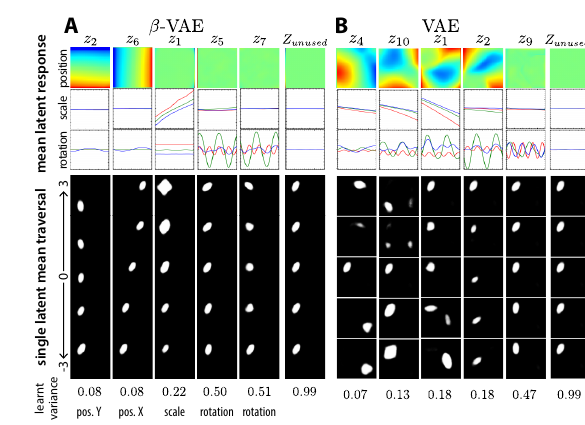

## Review corrections

The paper's MLP, Adagrad and pixel-summed Bernoulli/KL objective are retained. This revision adds native notebook figure/table display, complete checkpoint-owned training histories with atomic recovery, dataset content signatures, non-finite gradient checks, and checkpoint matching for response plots. Missing smoke-analysis bins are NaN rather than artificial zeros. Position maps share a symmetric color scale. The six-column view is a presentation subset, not a claim that five units are active; all ten coordinates are also plotted and saved. Learned inactivity must be judged from both KL/variance and traversals.

Training and analysis remain disabled by default. CPU code-cell checks passed; the deliverable is unexecuted. Jupyter kernel execution could not be tested here because local socket creation is denied. These checks are not trained Figure 7 results. Run both training and analysis in one execution to obtain a submission notebook containing its own training logs and generated images. Full default training is 100 epochs × 3 seeds × 2 beta settings, an explicit budget choice that has not been benchmarked here. Run smoke first; a Slurm time limit may require resubmission using epoch checkpoints. No full dSprites training was performed during this review.


In [1]:
# 1. Imports and explicit execution gates (SAFE: training is OFF)
import os, sys, json, math, time, random, hashlib, zipfile, platform, shutil
from dataclasses import dataclass, asdict, replace
from pathlib import Path
from contextlib import nullcontext
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader, Subset

VERSION = "paper3_fig7_v2"
RUN_TRAINING = os.getenv("BETA_VAE_TRAIN", "0") == "1"        # OFF by default
RUN_ANALYSIS = os.getenv("BETA_VAE_ANALYZE", "0") == "1"      # OFF by default
MODE = os.getenv("BETA_VAE_MODE", "smoke").lower()            # smoke or full
assert MODE in {"smoke", "full"}

@dataclass(frozen=True)
class Config:
    version: str = VERSION
    mode: str = MODE
    dataset_npz: str = os.getenv("DSPRITES_NPZ", "./data/dsprites.npz")
    output_root: str = os.getenv("BETA_VAE_OUTPUT_ROOT", "./paper3_figure7_outputs_v2")
    batch_size: int = 128                   # choice; not specified by the paper
    analysis_batch_size: int = 512           # choice; inference only
    max_epochs_full: int = 100              # choice; not specified by the paper
    max_epochs_smoke: int = 2               # smoke-only budget
    train_examples_smoke: int = 4096        # smoke-only subset, held fixed across beta
    analysis_examples_smoke: int = 8192     # smoke-only partial factor averaging
    seeds_full: tuple = (0, 1, 2)          # choice: 3 seeds per beta
    seeds_smoke: tuple = (0,)               # choice: 1 seed per beta for smoke
    betas: tuple = (1.0, 4.0)
    num_workers: int = 2
    cache_rows_per_chunk: int = 1024
    print_every_batches: int = 200
    anchor_factors: tuple = (0, 1, 3, 0, 16, 16)   # [color,shape,scale,rotation,X,Y]
    analyze_all_seeds: bool = True         # analyses only after training, optional expensive
    display_seed: int = 0                  # chosen BEFORE seeing output; not cherry-picked

CFG = replace(Config(), num_workers=0)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path(CFG.output_root) / CFG.mode
print("Python:", sys.version.split()[0], "PyTorch:", torch.__version__,
      "CUDA available:", torch.cuda.is_available(), "Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0),
          "VRAM GiB:", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))
print("Slurm job:", os.getenv("SLURM_JOB_ID", "not set"))
print("MODE:", CFG.mode, "TRAINING ENABLED:", RUN_TRAINING,
      "ANALYSIS ENABLED:", RUN_ANALYSIS)
print("Dataset path (not yet accessed):", CFG.dataset_npz)
print("Outputs (not yet created):", OUT.resolve())
assert CFG.batch_size > 0 and CFG.analysis_batch_size > 0
assert CFG.display_seed in CFG.seeds_full

Python: 3.11.15 PyTorch: 2.11.0+cu128 CUDA available: True Device: cuda
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition VRAM GiB: 94.97
Slurm job: 21743
MODE: full TRAINING ENABLED: True ANALYSIS ENABLED: True
Dataset path (not yet accessed): /home/NAS/yangc21/cs6362/paper3_data/dsprites.npz
Outputs (not yet created): /home/NAS/yangc21/cs6362/paper3_figure7_outputs_v2/full


## 2. Model and exact objective

Encoder returns posterior mean μ(x) and log-variance log σ²(x), from two 1200-wide ReLU layers. Reparameterization uses ε∼N(0,I). Decoder uses three 1200-wide Tanh hidden layers and Bernoulli **logits** at the output. PyTorch's `binary_cross_entropy_with_logits` computes the negative log-likelihood numerically stably. Both the reconstruction term and KL are **summed over their respective dimensions** before averaging over the batch. In particular **do not use `BCE(reduction='mean')`**: it changes the β trade-off by a factor of 4096.

The paper's decoder activation line is compact and doesn't unambiguously specify exactly where Tanh is applied; this notebook applies it to the three hidden layers and no final Tanh so the output can parameterize a Bernoulli likelihood.

In [2]:
# 2. Model definitions
class BetaVAE(nn.Module):
    def __init__(self, latent_dim=10, width=1200):
        super().__init__()
        self.latent_dim = int(latent_dim)
        self.encoder = nn.Sequential(
            nn.Flatten(), nn.Linear(4096, width), nn.ReLU(),
            nn.Linear(width, width), nn.ReLU(),
        )
        self.mu_head = nn.Linear(width, latent_dim)
        self.logvar_head = nn.Linear(width, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, width), nn.Tanh(),
            nn.Linear(width, width), nn.Tanh(),
            nn.Linear(width, width), nn.Tanh(),
            nn.Linear(width, 4096),
        )

    def encode(self, x):
        hidden = self.encoder(x)
        return self.mu_head(hidden), self.logvar_head(hidden)

    def decode_logits(self, z):
        return self.decoder(z).view(-1, 1, 64, 64)

    def forward(self, x):
        mu, logvar = self.encode(x)
        eps = torch.randn_like(mu)
        z = mu + torch.exp(0.5 * logvar) * eps
        return self.decode_logits(z), mu, logvar


def vae_loss(logits, target, mu, logvar, beta):
    assert logits.shape == target.shape and mu.shape == logvar.shape
    reconstruction = F.binary_cross_entropy_with_logits(
        logits, target, reduction="none").flatten(1).sum(dim=1).mean()
    kl = -0.5 * (1 + logvar - mu.square() - logvar.exp()).sum(dim=1).mean()
    total = reconstruction + float(beta) * kl
    return total, reconstruction.detach(), kl.detach()


def count_parameters(module):
    return sum(p.numel() for p in module.parameters() if p.requires_grad)

# Safe CPU-only smoke of model shapes and gradients; does NOT train on dSprites.
torch.manual_seed(0)
_check_model = BetaVAE().cpu()
_check_input = torch.zeros(2, 1, 64, 64)
with torch.no_grad():
    _logits, _mu, _lv = _check_model(_check_input)
    _total, _recon, _kl = vae_loss(_logits, _check_input, _mu, _lv, beta=4)
assert _logits.shape == (2, 1, 64, 64)
assert _mu.shape == _lv.shape == (2, 10)
assert torch.isfinite(_total)
print("Parameter count:", count_parameters(_check_model))
print("Shape/loss checks passed; no optimizer steps executed.")
del _check_model, _check_input, _logits, _mu, _lv, _total, _recon, _kl

Parameter count: 14196516
Shape/loss checks passed; no optimizer steps executed.


## 3. Load the original binary dSprites dataset without a large RAM allocation

**Data are not downloaded by this notebook.** Supply a locally obtained `.npz` file via `DSPRITES_NPZ`. The paper describes the simulated shapes and their factors but not the `.npz` container format or official download URL; the file schema below is therefore a *reproduction/data-format assumption*. For security, use a trusted local dataset. The notebook reads `imgs.npy` from the `.npz` archive **in chunks** and writes a cached, bit-packed `.npy` of size ≈377 MB. This avoids holding the full ≈3 GB uncompressed image collection in memory for each Slurm job.

Expected shape-factor indexing (0-based): `color [1]`, `shape [3]`, `scale [6]`, `orientation [40]`, `posX [32]`, `posY [32]`. For analysis, the factor classes are read from `latents_classes` and checked against these cardinalities. This assumption is stated explicitly because the provided PDF doesn't prescribe an on-disk factor ordering. No ground-truth factors enter the training loss.

The cache uses a file lock on Linux and an atomic rename. Because intermediate `.npy` cache files can be large, point `BETA_VAE_OUTPUT_ROOT` to your writable scratch/NAS storage with adequate space.

In [3]:
# 3. CPU memory-efficient cache and dataset
FACTOR_SIZES = (1, 3, 6, 40, 32, 32)
FACTOR_NAMES = ("color", "shape", "scale", "orientation", "posX", "posY")
N_FULL = math.prod(FACTOR_SIZES)
SHAPE_NAMES = ("square", "oval", "heart")  # array class-id convention (not specified by paper)
SHAPE_COLORS = ("tab:red", "tab:green", "tab:blue")


def _array_header_from_npz(member):
    version = np.lib.format.read_magic(member)
    if version == (1, 0):
        return np.lib.format.read_array_header_1_0(member)
    if version == (2, 0):
        return np.lib.format.read_array_header_2_0(member)
    if version == (3, 0):
        return np.lib.format.read_array_header_2_0(member)
    raise ValueError("Unsupported NumPy .npy header version: " + str(version))


def make_packed_cache(npz_path, cache_dir, rows_per_chunk=1024):
    import fcntl  # Linux / Slurm POSIX locking
    npz_path, cache_dir = Path(npz_path), Path(cache_dir)
    if not npz_path.is_file():
        raise FileNotFoundError(f"No dSprites NPZ file at {npz_path}. Set DSPRITES_NPZ.")
    cache_dir.mkdir(parents=True, exist_ok=True)
    cache_file = cache_dir / "dsprites_binary_packed_v1.npy"
    cache_meta = cache_dir / "dsprites_binary_packed_v1.json"
    signature = {
        "npz_path": str(npz_path.resolve()),
        "npz_size": npz_path.stat().st_size,
        "npz_mtime_ns": npz_path.stat().st_mtime_ns,
        "cache_version": 1,
    }
    with open(cache_dir / ".dsprites_cache.lock", "a+b") as lock:
        fcntl.flock(lock.fileno(), fcntl.LOCK_EX)
        if cache_file.is_file() and cache_meta.is_file():
            try:
                if json.loads(cache_meta.read_text()) == signature:
                    cached = np.load(cache_file, mmap_mode="r")
                    assert cached.shape == (N_FULL, 512)
                    return cache_file
            except (ValueError, AssertionError, OSError, json.JSONDecodeError):
                pass
        tmp = cache_file.with_name(cache_file.stem + ".incomplete.npy")
        print("Streaming and packing binary images; may take several minutes:", npz_path)
        with zipfile.ZipFile(npz_path) as zf:
            image_members = [x for x in zf.namelist() if Path(x).name == "imgs.npy"]
            if len(image_members) != 1:
                raise ValueError("Expected exactly one imgs.npy member in dSprites NPZ")
            with zf.open(image_members[0]) as stream:
                shape, fortran, dtype = _array_header_from_npz(stream)
                if tuple(shape) != (N_FULL, 64, 64) or fortran:
                    raise ValueError(f"Unexpected image shape/order: {shape}, Fortran={fortran}")
                dtype = np.dtype(dtype)
                if dtype.itemsize != 1 or dtype.kind not in ("b", "u", "i"):
                    raise ValueError(f"Expected one-byte binary image elements, got {dtype}")
                mmap = np.lib.format.open_memmap(
                    tmp, mode="w+", dtype=np.uint8, shape=(N_FULL, 512))
                for start in range(0, N_FULL, rows_per_chunk):
                    count = min(rows_per_chunk, N_FULL - start)
                    nbytes = count * 4096 * dtype.itemsize
                    raw = stream.read(nbytes)
                    if len(raw) != nbytes:
                        raise IOError("Truncated imgs.npy member")
                    pixels = np.frombuffer(raw, dtype=dtype).reshape(count, 4096)
                    if not np.all((pixels == 0) | (pixels == 1)):
                        raise ValueError("Expected strictly binary dSprites images (0/1)")
                    mmap[start:start + count] = np.packbits(pixels != 0, axis=1)
                del mmap
        os.replace(tmp, cache_file)
        cache_meta.write_text(json.dumps(signature, indent=2))
    return cache_file


class DSpritesPacked(Dataset):
    def __init__(self, packed_path):
        self.packed_path = str(packed_path)
        self.images = np.load(self.packed_path, mmap_mode="r")
        assert self.images.shape == (N_FULL, 512)

    def __len__(self):
        return N_FULL

    def __getitem__(self, index):
        packed = self.images[int(index)]
        pixels = np.unpackbits(packed, count=4096).reshape(1, 64, 64).copy()
        return torch.from_numpy(pixels), int(index)

    def __getitems__(self, indices):
        # PyTorch's batched dataset-fetch path: unpack bits once per batch.
        inds = np.asarray(indices, dtype=np.int64)
        batch = np.unpackbits(self.images[inds], axis=1, count=4096).reshape(-1, 1, 64, 64)
        return [(torch.from_numpy(batch[i].copy()), int(inds[i])) for i in range(len(inds))]


def read_factor_classes(npz_path):
    with np.load(npz_path, allow_pickle=False) as archive:
        if "latents_classes" not in archive:
            raise KeyError("Expected dSprites key latents_classes; file schema choice documented above")
        factors = np.asarray(archive["latents_classes"], dtype=np.int64)
    if factors.shape != (N_FULL, 6):
        raise ValueError(f"latents_classes has unexpected shape {factors.shape}")
    for col, (name, size) in enumerate(zip(FACTOR_NAMES, FACTOR_SIZES)):
        values = np.unique(factors[:, col])
        if not np.array_equal(values, np.arange(size)):
            raise ValueError(f"Unexpected {name} indices; expected 0..{size-1}, got {values}")
    keys = np.ravel_multi_index(factors.T, FACTOR_SIZES)
    if np.unique(keys).size != N_FULL:
        raise ValueError("Factors are not a unique full Cartesian product")
    return factors, keys


def make_data():
    npz = Path(CFG.dataset_npz)
    cache = make_packed_cache(npz, Path(CFG.output_root) / "_data_cache", CFG.cache_rows_per_chunk)
    dataset = DSpritesPacked(cache)
    factors, flat_keys = read_factor_classes(npz)
    return dataset, factors, flat_keys

# No filesystem access to DSPRITES_NPZ occurs unless training or analysis gates are enabled.

## 4. Seeds, experiment identity, and checkpoints

The same seed yields the same **initial parameter vector** for β=1 and β=4; only the β coefficient differs. This paired initialization is a **reproduction choice**, not a claim that the authors shared initializations. The pseudorandom minibatch order is deterministic per epoch. Epoch-level checkpoints are restartable without confusing smoke and full runs, and include optimizer state and a configuration signature. A completed checkpoint is reused only with a matching signature. No run can silently load checkpoints from a different mode or architecture version.

In [4]:
# 4. Reproducibility, run directories, checkpoint helpers

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed % (2**32 - 1))
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def dataset_identity():
    path = Path(CFG.dataset_npz).resolve()
    stat = path.stat()
    key = (str(path), stat.st_size, stat.st_mtime_ns)
    cache = globals().setdefault("_DATASET_IDENTITIES", {})
    if key not in cache:
        digest = hashlib.sha256()
        with path.open("rb") as stream:
            for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
                digest.update(chunk)
        cache[key] = {"path": str(path), "size": stat.st_size,
                      "sha256": digest.hexdigest()}
    return cache[key]


def model_identity(model):
    digest = hashlib.sha256()
    for name, tensor in sorted(model.state_dict().items()):
        arr = tensor.detach().cpu().contiguous().numpy()
        digest.update(name.encode())
        digest.update(str((arr.shape, arr.dtype)).encode())
        digest.update(arr.tobytes())
    return digest.hexdigest()


def atomic_json(value, path):
    path = Path(path)
    temp = path.with_suffix(path.suffix + ".incomplete")
    temp.write_text(json.dumps(value, indent=2))
    os.replace(temp, path)


def write_history(rows, path):
    path = Path(path)
    temp = path.with_suffix(".csv.incomplete")
    pd.DataFrame(rows).to_csv(temp, index=False)
    os.replace(temp, path)


def run_spec(beta, seed):
    return {
        "version": CFG.version, "mode": CFG.mode, "beta": float(beta),
        "seed": int(seed), "architecture": "MLP-1200-1200-10-1200-1200-1200",
        "optimizer": "Adagrad", "lr": 1e-2, "batch_size": CFG.batch_size,
        "training_examples": (CFG.train_examples_smoke if CFG.mode == "smoke" else N_FULL),
        "epoch_budget": (CFG.max_epochs_smoke if CFG.mode == "smoke" else CFG.max_epochs_full),
        "dataset": dataset_identity(), "subset_seed": 2027,
        "reconstruction": "Bernoulli_sum_pixels", "kl": "sum_dimensions",
    }


def spec_signature(spec):
    return hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()


def run_dir(beta, seed):
    return OUT / f"beta_{int(beta)}" / f"seed_{int(seed)}"


def atomic_save(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".incomplete")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def read_checkpoint(path, device="cpu"):
    # Only load notebook-generated, trusted checkpoint files.
    return torch.load(path, map_location=device, weights_only=False)


def load_run_model(beta, seed, device=DEVICE):
    rd = run_dir(beta, seed)
    path = rd / "final.pt"
    if not path.is_file():
        raise FileNotFoundError(f"Missing final checkpoint {path}; train first")
    ckpt = read_checkpoint(path, device="cpu")
    expected = spec_signature(run_spec(beta, seed))
    if ckpt.get("signature") != expected:
        raise RuntimeError(f"Checkpoint signature mismatch for {path}")
    model = BetaVAE().to(device)
    model.load_state_dict(ckpt["model"])
    if ckpt.get("epoch", -1) + 1 != run_spec(beta, seed)["epoch_budget"]:
        raise RuntimeError("Final checkpoint has not completed the configured budget")
    model.eval()
    return model, ckpt


def selected_seeds():
    return CFG.seeds_smoke if CFG.mode == "smoke" else CFG.seeds_full


def training_subset(dataset, seed=2027):
    if CFG.mode == "full":
        return dataset
    rng = np.random.default_rng(seed)
    ids = np.sort(rng.choice(N_FULL, size=CFG.train_examples_smoke, replace=False))
    return Subset(dataset, ids.tolist())


def loader_for(dataset, bs, shuffle=False, seed=0, workers=None):
    generator = torch.Generator().manual_seed(int(seed))
    return DataLoader(dataset, batch_size=bs, shuffle=shuffle, generator=generator,
                      num_workers=CFG.num_workers if workers is None else workers,
                      pin_memory=(DEVICE.type == "cuda"), drop_last=False)

## 5. Training: complete dataset in full mode; small separate subset in smoke mode

Training is gated by `BETA_VAE_TRAIN=1` (default **OFF**). For the full mode, all 737,280 samples are used each epoch; no reconstruction labels or simulator factors are passed into the VAE. For the smoke mode, the same fixed 4,096-example subset is used for both β values, for two epochs, and stored in a **different output tree**. Full mode defaults to 3 seeds per β, 100 epochs maximum. Epoch count, batch size, paired initialization and seed count are reproduction decisions.

Training metadata includes epochs, cumulative optimizer steps, reconstruction term, KL term, total objective and current run state. `final.pt` is written only after all configured epochs complete. No early stopping is applied; this avoids disguising an arbitrary stopping heuristic as a reported author choice.

In [5]:
# 5. Training loop; does not run until RUN_TRAINING=True

def train_one(dataset, beta, seed):
    spec = run_spec(beta, seed)
    sig = spec_signature(spec)
    rd = run_dir(beta, seed)
    rd.mkdir(parents=True, exist_ok=True)
    if (rd / "final.pt").is_file():
        saved = read_checkpoint(rd / "final.pt")
        if saved.get("signature") != sig:
            raise RuntimeError("Existing final checkpoint has incompatible configuration")
        if saved.get("epoch", -1) + 1 != spec["epoch_budget"]:
            raise RuntimeError("Incomplete final checkpoint")
        write_history(saved["history"], rd / "history.csv")
        print("Completed run already exists:", rd)
        return

    seed_everything(seed)
    model = BetaVAE().to(DEVICE)
    opt = torch.optim.Adagrad(model.parameters(), lr=1e-2)
    ds = training_subset(dataset)
    epochs = CFG.max_epochs_smoke if CFG.mode == "smoke" else CFG.max_epochs_full
    history_file = rd / "history.csv"
    history = []
    step = 0
    first_epoch = 0
    if (rd / "last.pt").is_file():
        old = read_checkpoint(rd / "last.pt")
        if old.get("signature") != sig:
            raise RuntimeError(f"Refusing incompatible checkpoint: {rd / 'last.pt'}")
        model.load_state_dict(old["model"])
        opt.load_state_dict(old["optimizer"])
        first_epoch, step = int(old["epoch"]) + 1, int(old["optimizer_step"])
        history = old["history"]
        if [int(r["epoch"]) for r in history] != list(range(1, first_epoch + 1)):
            raise RuntimeError("Checkpoint history is inconsistent with completed epochs")
        write_history(history, history_file)
        print(f"Resume β={beta}, seed={seed}: epoch {first_epoch}, step {step}")

    atomic_json({**spec, "signature": sig}, rd / "spec.json")
    elapsed_before = float(history[-1]["elapsed_seconds"]) if history else 0.0
    t0 = time.time()
    for epoch in range(first_epoch, epochs):
        # Per-epoch seed makes shuffling and reparameterization reproducible on resume.
        seed_everything(seed * 100_003 + epoch * 1009)
        dl = loader_for(ds, CFG.batch_size, shuffle=True, seed=seed * 100_003 + epoch)
        model.train()
        totals = np.zeros(3, dtype=np.float64)
        seen = 0
        for batch_number, (x, _indices) in enumerate(dl, start=1):
            x = x.to(DEVICE, non_blocking=True).float()
            opt.zero_grad(set_to_none=True)
            logits, mu, logvar = model(x)
            loss, rec, kl = vae_loss(logits, x, mu, logvar, beta)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Non-finite loss at epoch {epoch+1}, step {step+1}")
            loss.backward()
            if any(p.grad is not None and not torch.isfinite(p.grad).all()
                   for p in model.parameters()):
                raise FloatingPointError("Non-finite gradient; no optimizer step performed")
            opt.step()
            if any(not torch.isfinite(p).all() for p in model.parameters()):
                raise FloatingPointError("Non-finite parameters; checkpoint not saved")
            step += 1
            totals += np.array([loss.item(), rec.item(), kl.item()]) * len(x)
            seen += len(x)
            if batch_number % CFG.print_every_batches == 0:
                print(f"β={beta:g} seed={seed} epoch={epoch+1}/{epochs} "
                      f"batch={batch_number}/{len(dl)} mean_objective={totals[0]/seen:.3f}", flush=True)
        row = {
            "beta": float(beta), "seed": int(seed), "epoch": epoch + 1,
            "optimizer_step": step, "examples": seen,
            "total": totals[0] / seen, "reconstruction": totals[1] / seen,
            "kl": totals[2] / seen, "elapsed_seconds": elapsed_before + time.time() - t0,
            "mode": CFG.mode, "version": CFG.version,
        }
        history.append(row)
        state = {
            "model": {k: v.detach().cpu() for k, v in model.state_dict().items()},
            "optimizer": opt.state_dict(), "epoch": epoch,
            "optimizer_step": step, "history_row": row, "history": history,
            "spec": spec, "signature": sig,
        }
        atomic_save(state, rd / "last.pt")
        write_history(history, history_file)
        print(f"[checkpoint] β={beta:g} seed={seed} epoch={epoch+1}/{epochs} "
              f"loss={row['total']:.3f}, reconstruction={row['reconstruction']:.3f}, "
              f"KL={row['kl']:.3f}, steps={step}", flush=True)
        del dl
    # If resume starts after the configured final epoch, promote last.pt after signature check.
    last = read_checkpoint(rd / "last.pt")
    if last["signature"] != sig or last["epoch"] + 1 != epochs:
        raise RuntimeError("Cannot mark incomplete training as finished")
    atomic_save(last, rd / "final.pt")
    print("FINISHED:", rd)


def train_all(dataset):
    for seed in selected_seeds():
        for beta in CFG.betas:
            train_one(dataset, beta, seed)

if RUN_TRAINING:
    assert Path(CFG.dataset_npz).is_file(), "Set DSPRITES_NPZ to a local .npz file"
    _ds_train, _factor_rows, _flat_keys = make_data()
    train_all(_ds_train)
    del _ds_train, _factor_rows, _flat_keys
else:
    print("TRAINING SKIPPED: set BETA_VAE_TRAIN=1 to enable explicitly.")

β=1 seed=0 epoch=1/100 batch=200/5760 mean_objective=569.015


β=1 seed=0 epoch=1/100 batch=400/5760 mean_objective=410.794


β=1 seed=0 epoch=1/100 batch=600/5760 mean_objective=332.165


β=1 seed=0 epoch=1/100 batch=800/5760 mean_objective=286.647


β=1 seed=0 epoch=1/100 batch=1000/5760 mean_objective=257.348


...

β=4 seed=2 epoch=100/100 batch=5200/5760 mean_objective=98.298


β=4 seed=2 epoch=100/100 batch=5400/5760 mean_objective=98.297


β=4 seed=2 epoch=100/100 batch=5600/5760 mean_objective=98.299


[checkpoint] β=4 seed=2 epoch=100/100 loss=98.305, reconstruction=47.601, KL=12.676, steps=576000


FINISHED: /home/NAS/yangc21/cs6362/paper3_figure7_outputs_v2/full/beta_4/seed_2


## 6. Empirical factor responses from the learned posterior

After a complete run, inference is performed using `μ(x)` (not stochastic samples). The notebook accumulates means for **each of all ten** latent dimensions and the original factors:

* Position: 32×32 maps, averaged across identities, scales and rotations.
* Scale: 3 identities × 6 scale levels, averaged over rotation and both positions.
* Rotation: 3 identities × 40 angles, averaged over scale and both positions.
* Shape (additional diagnostic): 3 means, averaged over all other factors.

The paper's figure does not display an independent shape-response row; we save shape means as a supplementary diagnostic. In full mode all these averages use **every dataset example**. In smoke mode they are explicitly labeled **partial** and are not reproduction-quality estimates.

For latent ordering, use `mean_posterior_variance[j] = mean_x exp(logvar_j(x))`. This is not equal to `Var_x(mu_j(x))` or to the KL contribution. We also report KL per latent to distinguish inactive and informative units. Figure 7 orders columns by learned Gaussian variance, with lower-variance (informative) columns first. The exact aggregation rule was not given, so this full-dataset mean is a documented choice.

In [6]:
# 6. Response statistics; independent of training labels

def select_analysis_ids():
    if CFG.mode == "full":
        return np.arange(N_FULL, dtype=np.int64)
    return np.sort(np.random.default_rng(440).choice(
        N_FULL, size=CFG.analysis_examples_smoke, replace=False)).astype(np.int64)


@torch.no_grad()
def analyze_model(model, dataset, factor_classes, flat_keys, beta, seed):
    outdir = run_dir(beta, seed) / "analysis"
    outdir.mkdir(parents=True, exist_ok=True)
    ids = select_analysis_ids()
    batch_dataset = Subset(dataset, ids.tolist())
    dl = loader_for(batch_dataset, CFG.analysis_batch_size, shuffle=False)
    model.eval()
    checkpoint_hash = model_identity(model)
    pos_sum, pos_count = np.zeros((10, 1024)), np.zeros(1024)
    scale_sum, scale_count = np.zeros((10, 18)), np.zeros(18)
    rot_sum, rot_count = np.zeros((10, 120)), np.zeros(120)
    shape_sum, shape_count = np.zeros((10, 3)), np.zeros(3)
    variance_sum, kl_sum, mu_sum = np.zeros(10), np.zeros(10), np.zeros(10)
    loss_sum = 0.0
    observed = 0
    for batch_no, (x, raw_idx) in enumerate(dl, 1):
        x = x.to(DEVICE, non_blocking=True).float()
        mu, logvar = model.encode(x)
        z = mu.detach().cpu().numpy().astype(np.float64)
        lv = logvar.detach().cpu().numpy().astype(np.float64)
        v = np.exp(lv)
        if not (np.isfinite(z).all() and np.isfinite(v).all()):
            raise FloatingPointError("Non-finite posterior during analysis")
        variance_sum += v.sum(axis=0)
        kl_sum += (0.5 * (v + z*z - 1 - lv)).sum(axis=0)
        mu_sum += z.sum(axis=0)
        factors = factor_classes[raw_idx.numpy()]
        shape_ids, scale_ids, rot_ids, xpos, ypos = (
            factors[:, 1], factors[:, 2], factors[:, 3], factors[:, 4], factors[:, 5])
        # Scalar keys for counts and vectorized per-latent binned sums.
        kp, ks, kr, kh = xpos * 32 + ypos, shape_ids * 6 + scale_ids, shape_ids * 40 + rot_ids, shape_ids
        for key, counts in ((kp, pos_count), (ks, scale_count),
                            (kr, rot_count), (kh, shape_count)):
            counts += np.bincount(key, minlength=len(counts))
        for j in range(10):
            pos_sum[j] += np.bincount(kp, weights=z[:, j], minlength=1024)
            scale_sum[j] += np.bincount(ks, weights=z[:, j], minlength=18)
            rot_sum[j] += np.bincount(kr, weights=z[:, j], minlength=120)
            shape_sum[j] += np.bincount(kh, weights=z[:, j], minlength=3)
        n = len(z)
        observed += n
        # A diagnostic, deterministic reconstruction with z=posterior mean.
        logits = model.decode_logits(mu)
        rec = F.binary_cross_entropy_with_logits(logits, x, reduction="sum").item()
        loss_sum += rec
        if batch_no % 250 == 0:
            print(f"Analysis β={beta:g} seed={seed}, processed {observed}/{len(ids)}", flush=True)

    def bin_mean(sums, counts):
        result = np.full_like(sums, np.nan)
        np.divide(sums, counts[None, :], out=result, where=counts[None, :] > 0)
        return result

    means = {
        "position": bin_mean(pos_sum, pos_count).reshape(10, 32, 32),
        "scale": bin_mean(scale_sum, scale_count).reshape(10, 3, 6),
        "rotation": bin_mean(rot_sum, rot_count).reshape(10, 3, 40),
        "shape": bin_mean(shape_sum, shape_count),
    }
    np.savez(outdir / "factor_bin_counts.npz", position=pos_count,
             scale=scale_count, rotation=rot_count, shape=shape_count)
    if CFG.mode == "full":
        assert observed == N_FULL and np.all(pos_count == 720)
        assert np.all(scale_count == 40960) and np.all(rot_count == 6144)
    posterior_variance = variance_sum / observed
    latent_kl = kl_sum / observed
    ordering = np.argsort(posterior_variance, kind="stable")
    # Resolve the selected reference example by actual factor IDs, not assumed row ordering.
    ref_key = np.ravel_multi_index(CFG.anchor_factors, FACTOR_SIZES)
    lookup = np.empty(N_FULL, dtype=np.int32)
    lookup[flat_keys] = np.arange(N_FULL, dtype=np.int32)
    ref_row = int(lookup[ref_key])
    ref_image, _ = dataset[ref_row]
    ref_image = ref_image.unsqueeze(0).to(DEVICE).float()
    anchor_mu, _ = model.encode(ref_image)
    anchor_mu = anchor_mu.squeeze(0).detach().cpu().numpy()
    np.save(outdir / "anchor_mu.npy", anchor_mu)
    for name, arr in means.items():
        np.save(outdir / f"{name}_mean.npy", arr)
    rows = [{
        "original_latent_index_1based": j + 1,
        "posterior_variance": float(posterior_variance[j]),
        "posterior_kl": float(latent_kl[j]),
        "posterior_mean": float(mu_sum[j] / observed),
        "variance_rank_1based": int(np.where(ordering == j)[0][0]) + 1,
        "beta": beta, "seed": seed,
    } for j in range(10)]
    pd.DataFrame(rows).to_csv(outdir / "latent_summary.csv", index=False)
    (outdir / "analysis_metadata.json").write_text(json.dumps({
        "mode": CFG.mode, "beta": beta, "seed": seed, "n_analyzed": observed,
        "checkpoint_sha256": checkpoint_hash,
        "training_signature": spec_signature(run_spec(beta, seed)),
        "n_full": N_FULL, "is_full_factorial": observed == N_FULL,
        "reference_factors": dict(zip(FACTOR_NAMES, CFG.anchor_factors)),
        "reference_row": ref_row,
        "mean_deterministic_reconstruction_bce_per_image": loss_sum / observed,
        "variance_order_1based": [int(x+1) for x in ordering],
        "caption": "Figure 7A/B full-factorial measurements" if observed == N_FULL
                   else "SMOKE ONLY: partial factor coverage; not paper reproduction",
    }, indent=2))
    print(f"Analyzed β={beta:g}, seed={seed}, n={observed}, "
          f"ordering (1-based)={[int(x+1) for x in ordering]}")
    return outdir

## 7. Paper-aligned Figure 7A/7B plots and traversals

For each β, display the **five lowest-variance** learned coordinates and the **highest-variance** coordinate (this does not establish inactivity), following Figure 7's compressed layout. Retain the identities of all ten latents in CSV files. Figure 7A in the paper happened to label its active dimensions `z2,z6,z1,z5,z7`; these indices are **not training targets** and must not be hard-coded into this reproduction. The position map and curves use empirical averages from Section 6.

For traversal, infer the posterior **mean** of one fixed real dataset image, replace only one coordinate with `[+3,+1.5,0,−1.5,−3]`, then decode those five latent vectors. The ordering from top to bottom matches the paper's graphical direction. There is no latent factor supervision or manually assigned latent label. The corresponding original factor labels (position/scale/rotation) are **never inserted based on desired appearance**.

In [7]:
# 7. Plotting from analysis artifacts (no fabricated curves)

TRAVERSAL_VALUES = np.linspace(3.0, -3.0, 5)

@torch.no_grad()
def decode_traversals(model, anchor_mu, dims, device=DEVICE):
    anchor = torch.tensor(anchor_mu, dtype=torch.float32, device=device)
    z = anchor.repeat(len(dims) * len(TRAVERSAL_VALUES), 1)
    for col, dim in enumerate(dims):
        start = col * len(TRAVERSAL_VALUES)
        z[start:start+len(TRAVERSAL_VALUES), int(dim)] = torch.tensor(
            TRAVERSAL_VALUES, dtype=torch.float32, device=device)
    imgs = torch.sigmoid(model.decode_logits(z)).cpu().numpy()
    return imgs.reshape(len(dims), len(TRAVERSAL_VALUES), 64, 64)


def plot_factor_panel(model, beta, seed, all_latents=False):
    rd = run_dir(beta, seed) / "analysis"
    required = [rd / "latent_summary.csv", rd / "position_mean.npy",
                rd / "scale_mean.npy", rd / "rotation_mean.npy", rd / "anchor_mu.npy",
                rd / "analysis_metadata.json"]
    missing = [str(p) for p in required if not p.is_file()]
    if missing:
        raise FileNotFoundError("Missing measured analysis artifacts: " + ", ".join(missing))
    stats = pd.read_csv(rd / "latent_summary.csv")
    metadata = json.loads((rd / "analysis_metadata.json").read_text())
    if metadata.get("checkpoint_sha256") != model_identity(model):
        raise RuntimeError("Analysis belongs to different checkpoint weights; rerun analysis")
    if metadata.get("training_signature") != spec_signature(run_spec(beta, seed)):
        raise RuntimeError("Analysis configuration/data mismatch; rerun analysis")
    stats = stats.sort_values("posterior_variance", kind="stable")
    top_five = stats.iloc[:5]["original_latent_index_1based"].to_numpy().astype(int) - 1
    unused_representative = int(stats.iloc[-1]["original_latent_index_1based"]) - 1
    selected = (list(stats["original_latent_index_1based"].astype(int) - 1)
                if all_latents else list(top_five) + [unused_representative])
    ncols = len(selected)
    pos = np.load(rd / "position_mean.npy")
    scl = np.load(rd / "scale_mean.npy")
    rot = np.load(rd / "rotation_mean.npy")
    anchor = np.load(rd / "anchor_mu.npy")
    traversals = decode_traversals(model, anchor, selected)
    np.save(rd / ("all_latents_traversals.npy" if all_latents else "figure7_displayed_traversals.npy"), traversals)

    fig = plt.figure(figsize=(2.9 * ncols, 11.3))
    gs = fig.add_gridspec(nrows=9, ncols=ncols,
                         height_ratios=[1.45, .77, .87, 1, 1, 1, 1, 1, .35],
                         hspace=.14, wspace=.16)
    for col, dim in enumerate(selected):
        variance = float(stats.set_index("original_latent_index_1based").loc[dim+1, "posterior_variance"])
        lbl = f"z{dim+1}" + (" (highest variance)" if not all_latents and col == 5 else "")
        ax0 = fig.add_subplot(gs[0, col])
        # One scale across all latent maps prevents tiny noise from appearing as strong signal.
        lim = max(float(np.nanmax(np.abs(pos))), 1e-8)
        ax0.imshow(pos[dim].T, origin="lower", cmap="jet", interpolation="nearest",
                   vmin=-lim, vmax=lim)
        ax0.set_title(lbl, fontsize=10, pad=3)
        ax0.set_xticks([]); ax0.set_yticks([])
        if col == 0: ax0.set_ylabel("Position\n32×32", fontsize=9)

        ax1 = fig.add_subplot(gs[1, col])
        for k, (label, color) in enumerate(zip(SHAPE_NAMES, SHAPE_COLORS)):
            ax1.plot(np.arange(6), scl[dim, k], color=color, linewidth=1.05,
                     label=label)
        ax1.set_xticks([0, 5]); ax1.tick_params(labelsize=6)
        if col == 0: ax1.set_ylabel("Scale\nmean μ", fontsize=9)

        ax2 = fig.add_subplot(gs[2, col])
        for k, (label, color) in enumerate(zip(SHAPE_NAMES, SHAPE_COLORS)):
            ax2.plot(np.arange(40), rot[dim, k],
                     color=color, linewidth=1.05, label=label)
        ax2.set_xticks([0, 19, 39]); ax2.tick_params(labelsize=6)
        if col == 0: ax2.set_ylabel("Rotation class\nmean μ", fontsize=9)

        for i, value in enumerate(TRAVERSAL_VALUES):
            ax = fig.add_subplot(gs[3+i, col])
            ax.imshow(traversals[col, i], cmap="gray", vmin=0, vmax=1,
                      interpolation="nearest")
            ax.set_xticks([]); ax.set_yticks([])
            if col == 0:
                ax.set_ylabel(f"z={value:+.1f}", fontsize=8)
        footer = fig.add_subplot(gs[8, col])
        footer.axis("off")
        footer.text(.5, .5, f"posterior var={variance:.3f}",
                    ha="center", va="center", fontsize=8)
    subtitle = "FULL FACTORIAL" if metadata["is_full_factorial"] else "SMOKE PARTIAL / NOT REPRODUCTION"
    fig.suptitle(f"Figure 7 {'A' if beta == 4 else 'B'} reproduction: β={beta:g}, seed={seed}  |  {subtitle}",
                 fontsize=14, y=.993)
    # One color legend applies to the scale and rotation response rows.
    from matplotlib.lines import Line2D
    legend = [Line2D([0], [0], color=c, lw=1.5, label=n)
              for n, c in zip(SHAPE_NAMES, SHAPE_COLORS)]
    fig.legend(handles=legend, loc="lower center", ncol=3, frameon=False,
               bbox_to_anchor=(.5, -.004), fontsize=9)
    suffix = "_all10" if all_latents else ""
    out = rd / f"figure7_beta{int(beta)}_seed{seed}{suffix}.png"
    fig.savefig(out, dpi=170, bbox_inches="tight")
    plt.close(fig)
    print("Saved:", out)
    return out


def plot_shape_diagnostic(beta, seed):
    rd = run_dir(beta, seed) / "analysis"
    shapes = np.load(rd / "shape_mean.npy")
    fig, ax = plt.subplots(figsize=(11, 4))
    x = np.arange(10)
    for k, (name, color) in enumerate(zip(SHAPE_NAMES, SHAPE_COLORS)):
        ax.plot(x+1, shapes[:, k], marker="o", ms=3, lw=1.2, color=color, label=name)
    ax.set(xlabel="Original latent coordinate (1-based)", ylabel="Mean posterior μ",
           title=f"Supplementary shape-factor response (β={beta:g}, seed={seed})")
    ax.set_xticks(np.arange(1, 11)); ax.legend(); ax.grid(alpha=.25)
    fig.tight_layout()
    fig.savefig(rd / "shape_factor_diagnostic.png", dpi=150)
    plt.close(fig)


def join_panels(p1, p4, outfile):
    from PIL import Image, ImageOps
    with Image.open(p4) as im4, Image.open(p1) as im1:
        left, right = im4.convert("RGB"), im1.convert("RGB")
        h = max(left.height, right.height)
        # No resizing of pixel data: preserve the generated panel images.
        canvas = Image.new("RGB", (left.width + right.width, h), "white")
        canvas.paste(left, (0, 0)); canvas.paste(right, (left.width, 0))
        canvas.save(outfile)
    print("Combined A/B comparison:", outfile)

## 8. Execute analysis from actual checkpoints (OFF by default)

Enable only once the appropriate trained `final.pt` checkpoints exist. For full mode, factor responses are computed for every seed and β. All seed-0 panels are then combined in one Figure 7A/B comparison; seed zero is predeclared, not selected retrospectively for aesthetic similarity. Other seeds remain in their own measured output directories. Full-data response inference is computationally costly; smoke responses are knowingly incomplete and **should never be submitted as full reproduction**.

Analysis β=1 seed=0, processed 128000/737280


Analysis β=1 seed=0, processed 256000/737280


Analysis β=1 seed=0, processed 384000/737280


Analysis β=1 seed=0, processed 512000/737280


Analysis β=1 seed=0, processed 640000/737280


...

Analysis β=4 seed=2, processed 640000/737280


Analyzed β=4, seed=2, n=737280, ordering (1-based)=[3, 10, 7, 4, 1, 6, 8, 9, 2, 5]


Saved: /home/NAS/yangc21/cs6362/paper3_figure7_outputs_v2/full/beta_4/seed_2/analysis/figure7_beta4_seed2.png


Saved: /home/NAS/yangc21/cs6362/paper3_figure7_outputs_v2/full/beta_4/seed_2/analysis/figure7_beta4_seed2_all10.png


Combined A/B comparison: /home/NAS/yangc21/cs6362/paper3_figure7_outputs_v2/full/Figure7AB_comparison_seed0.png


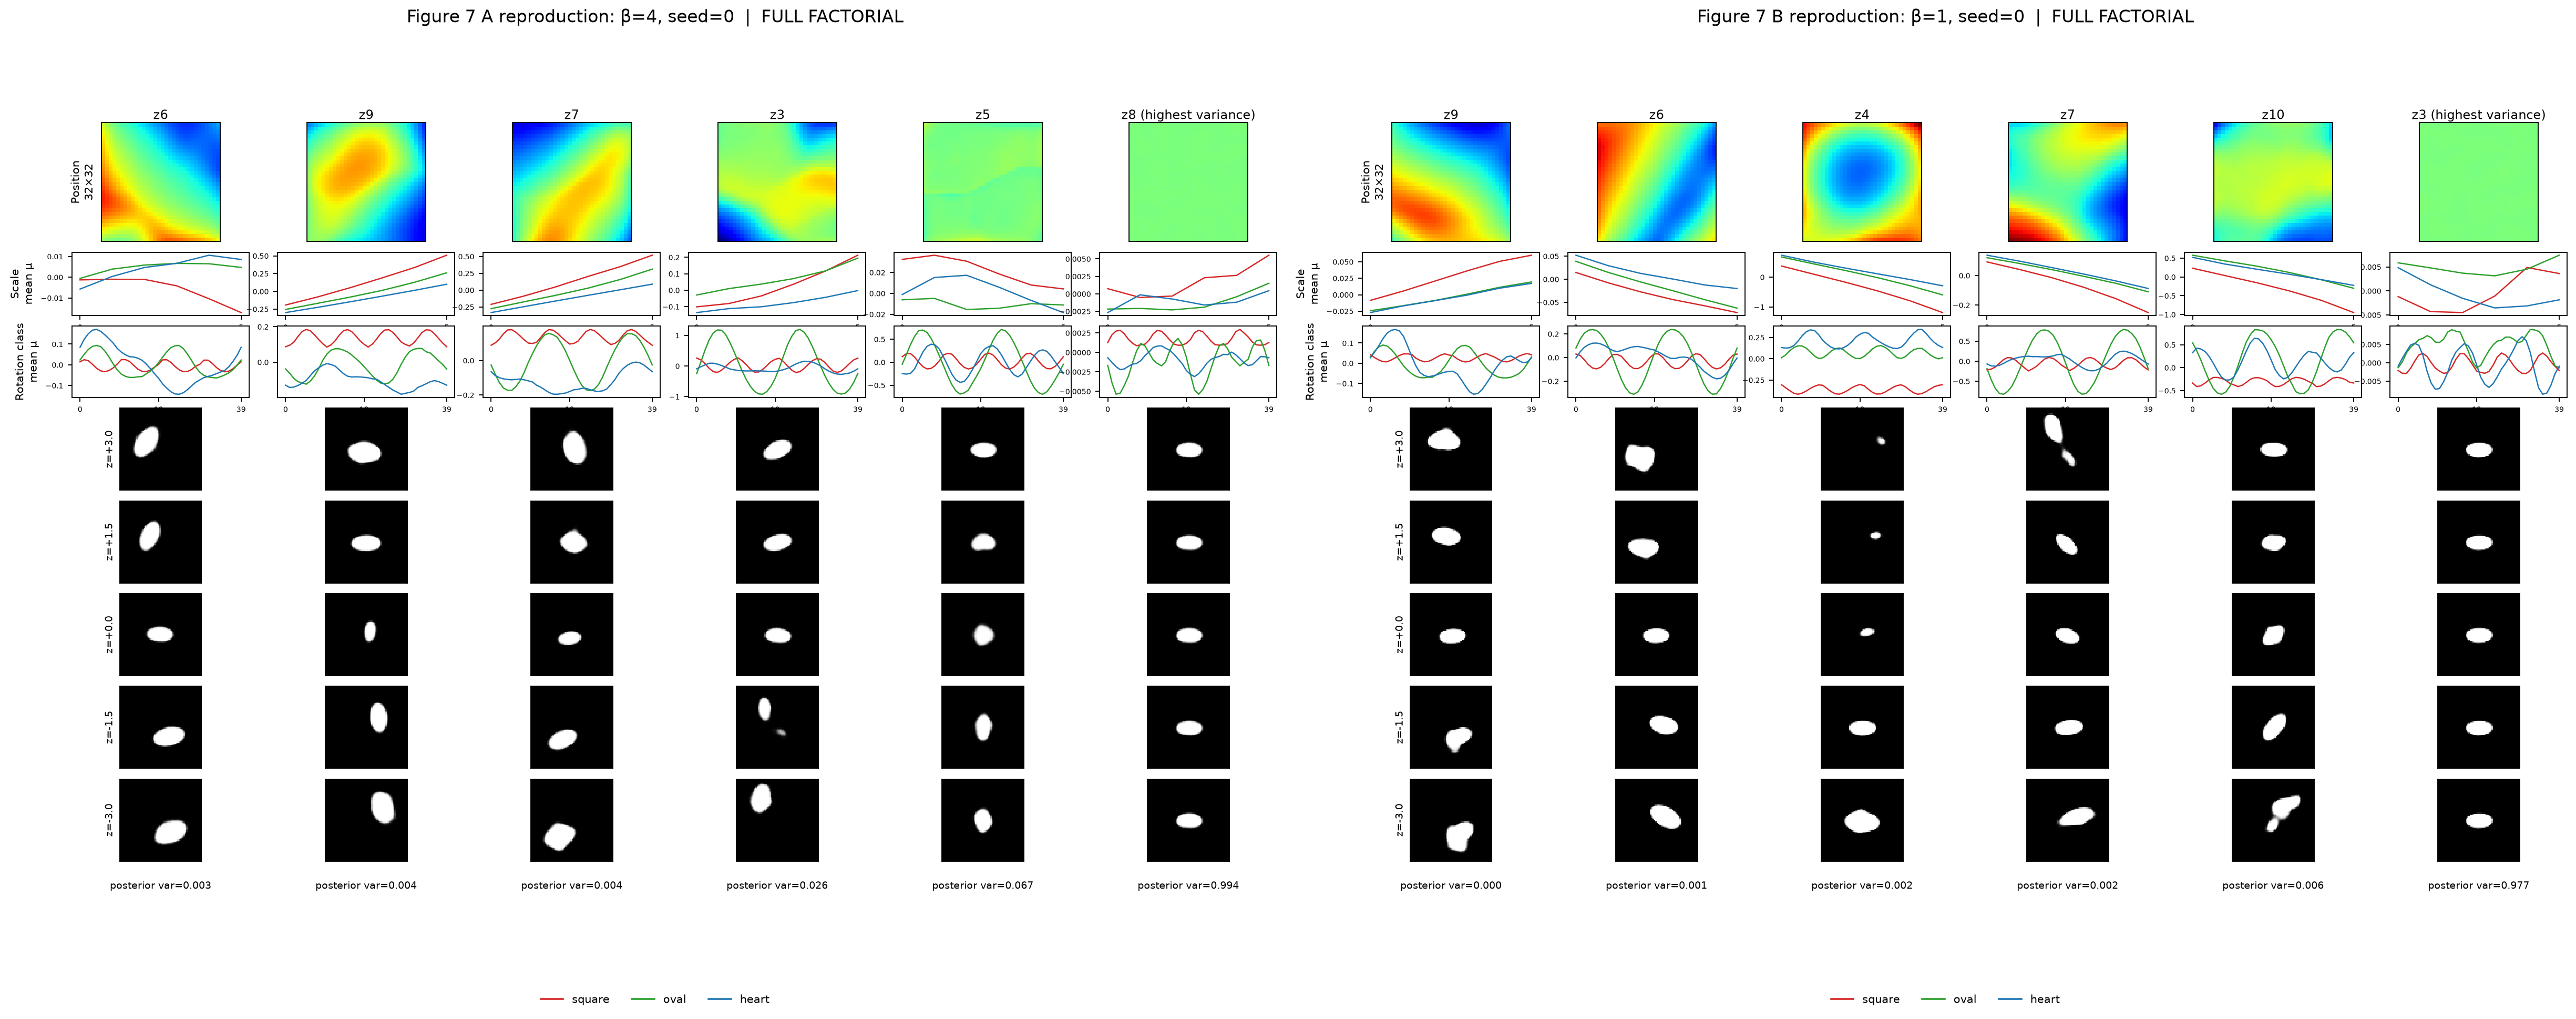

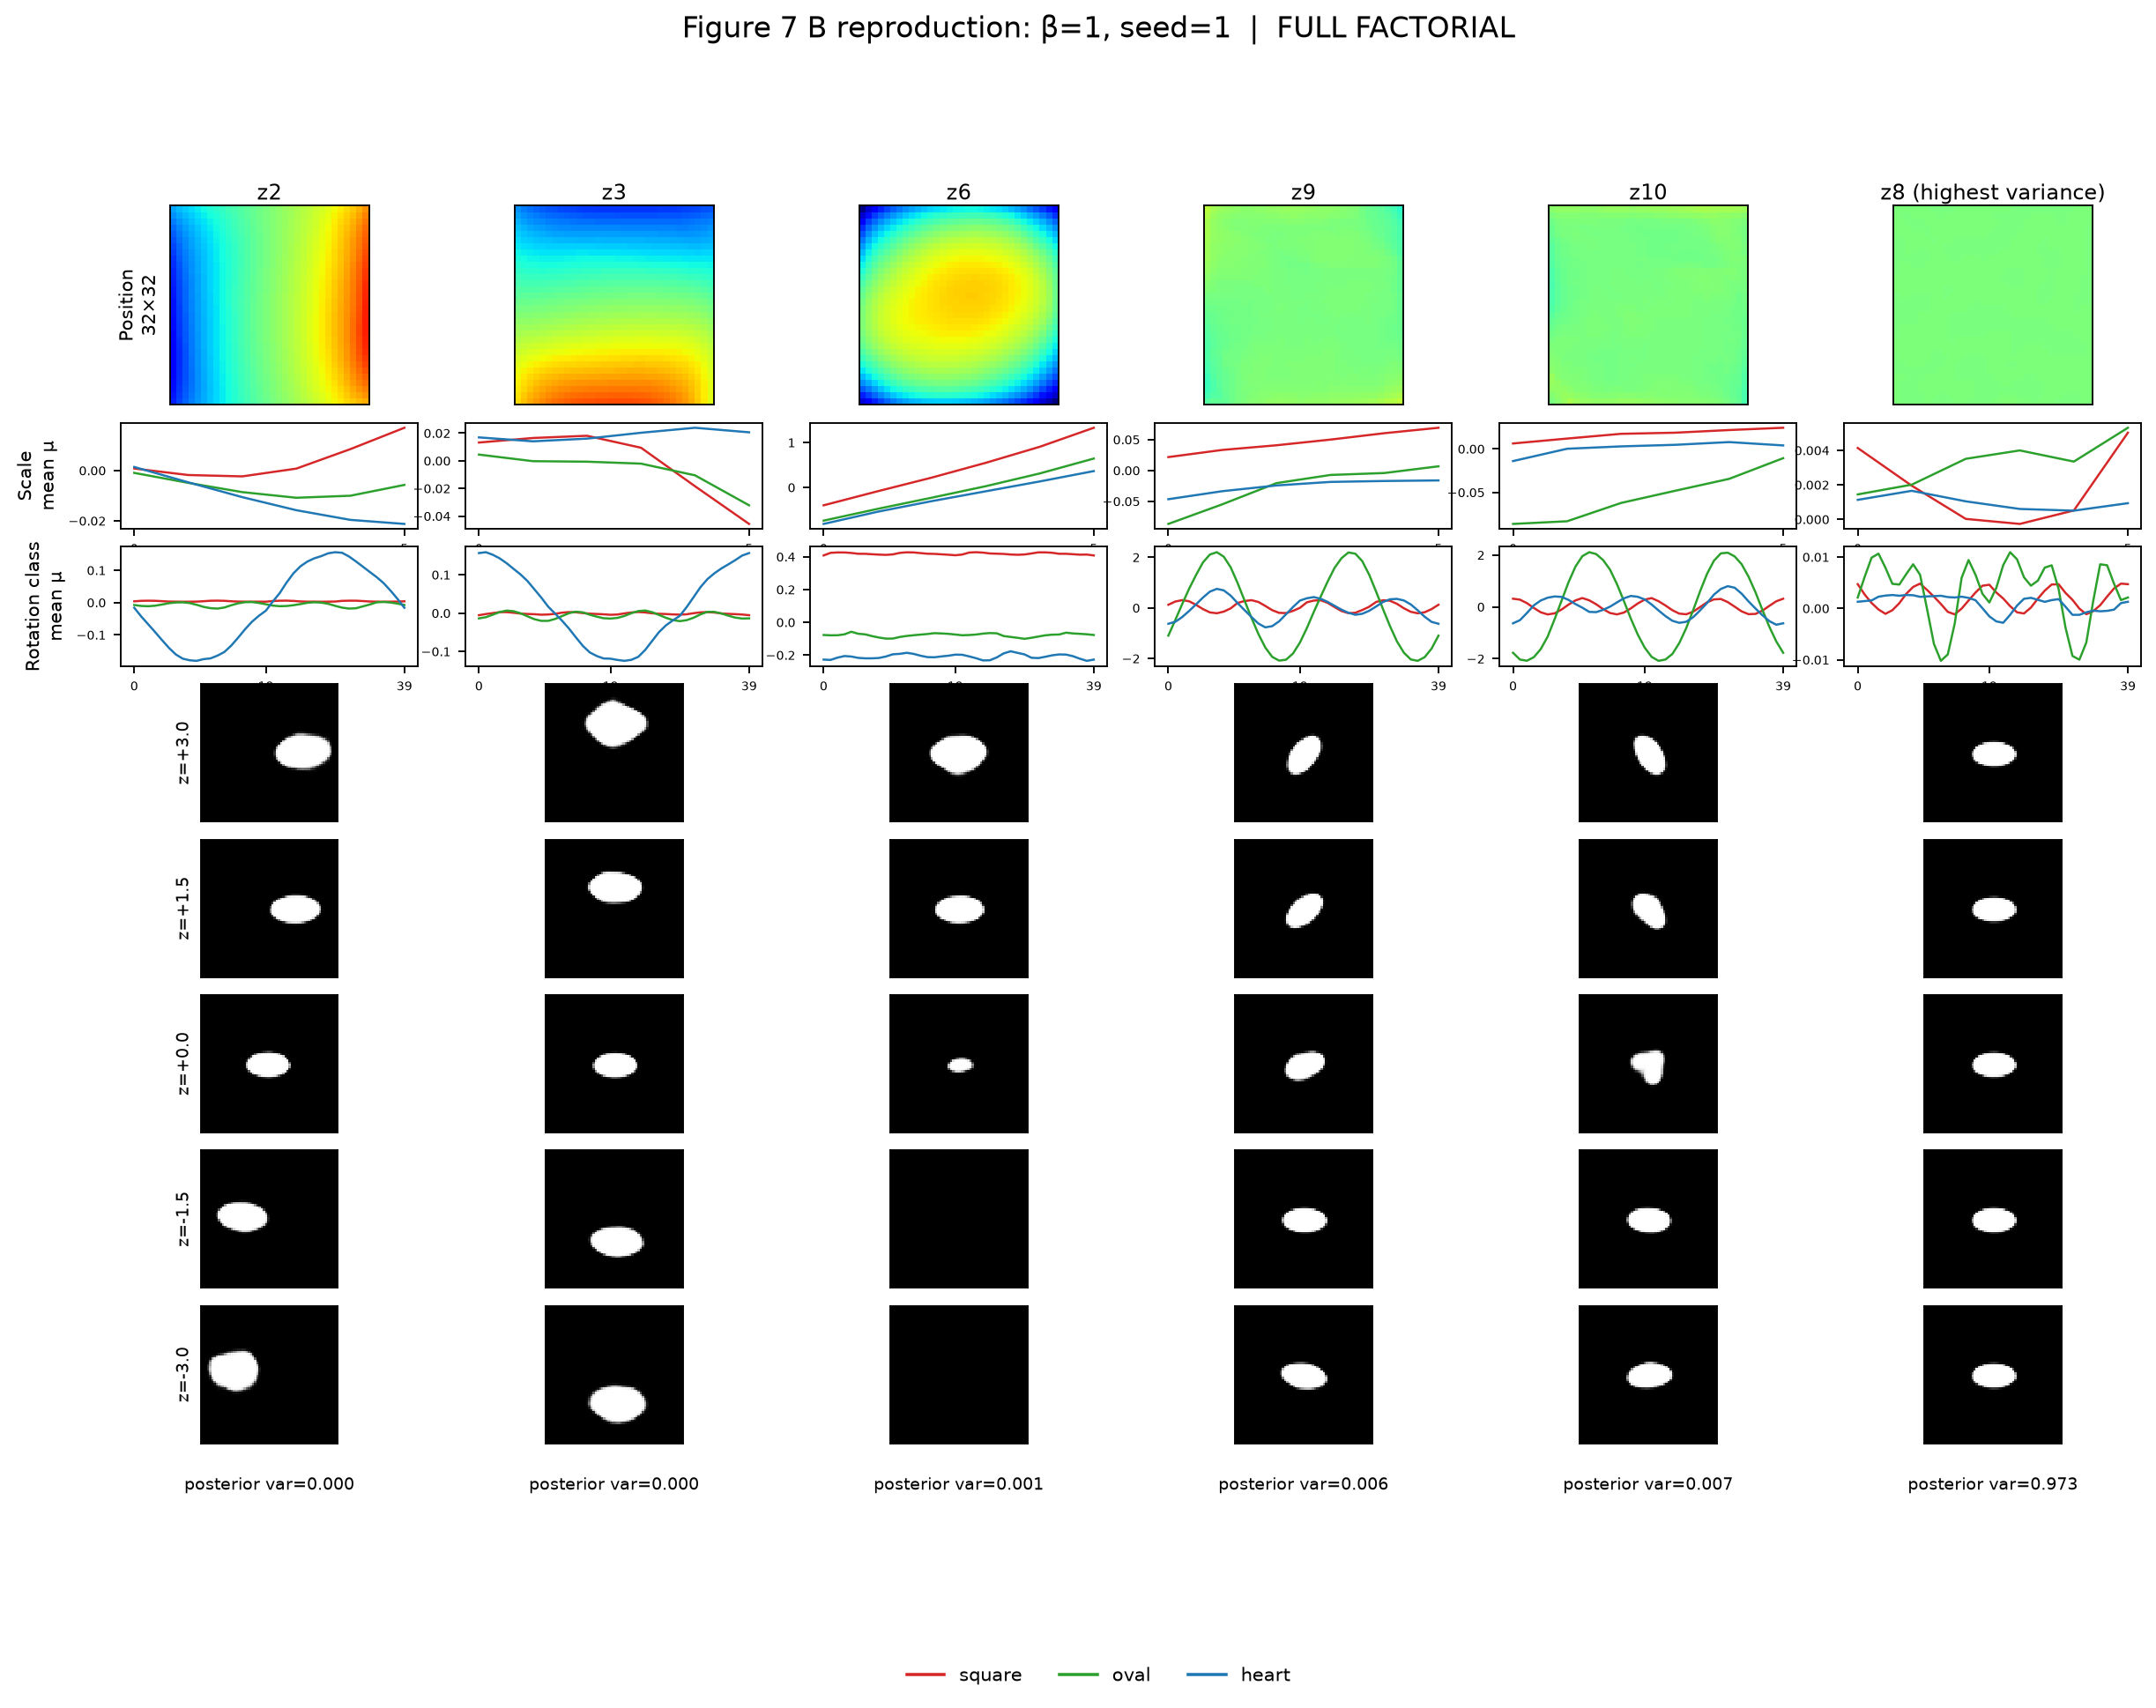

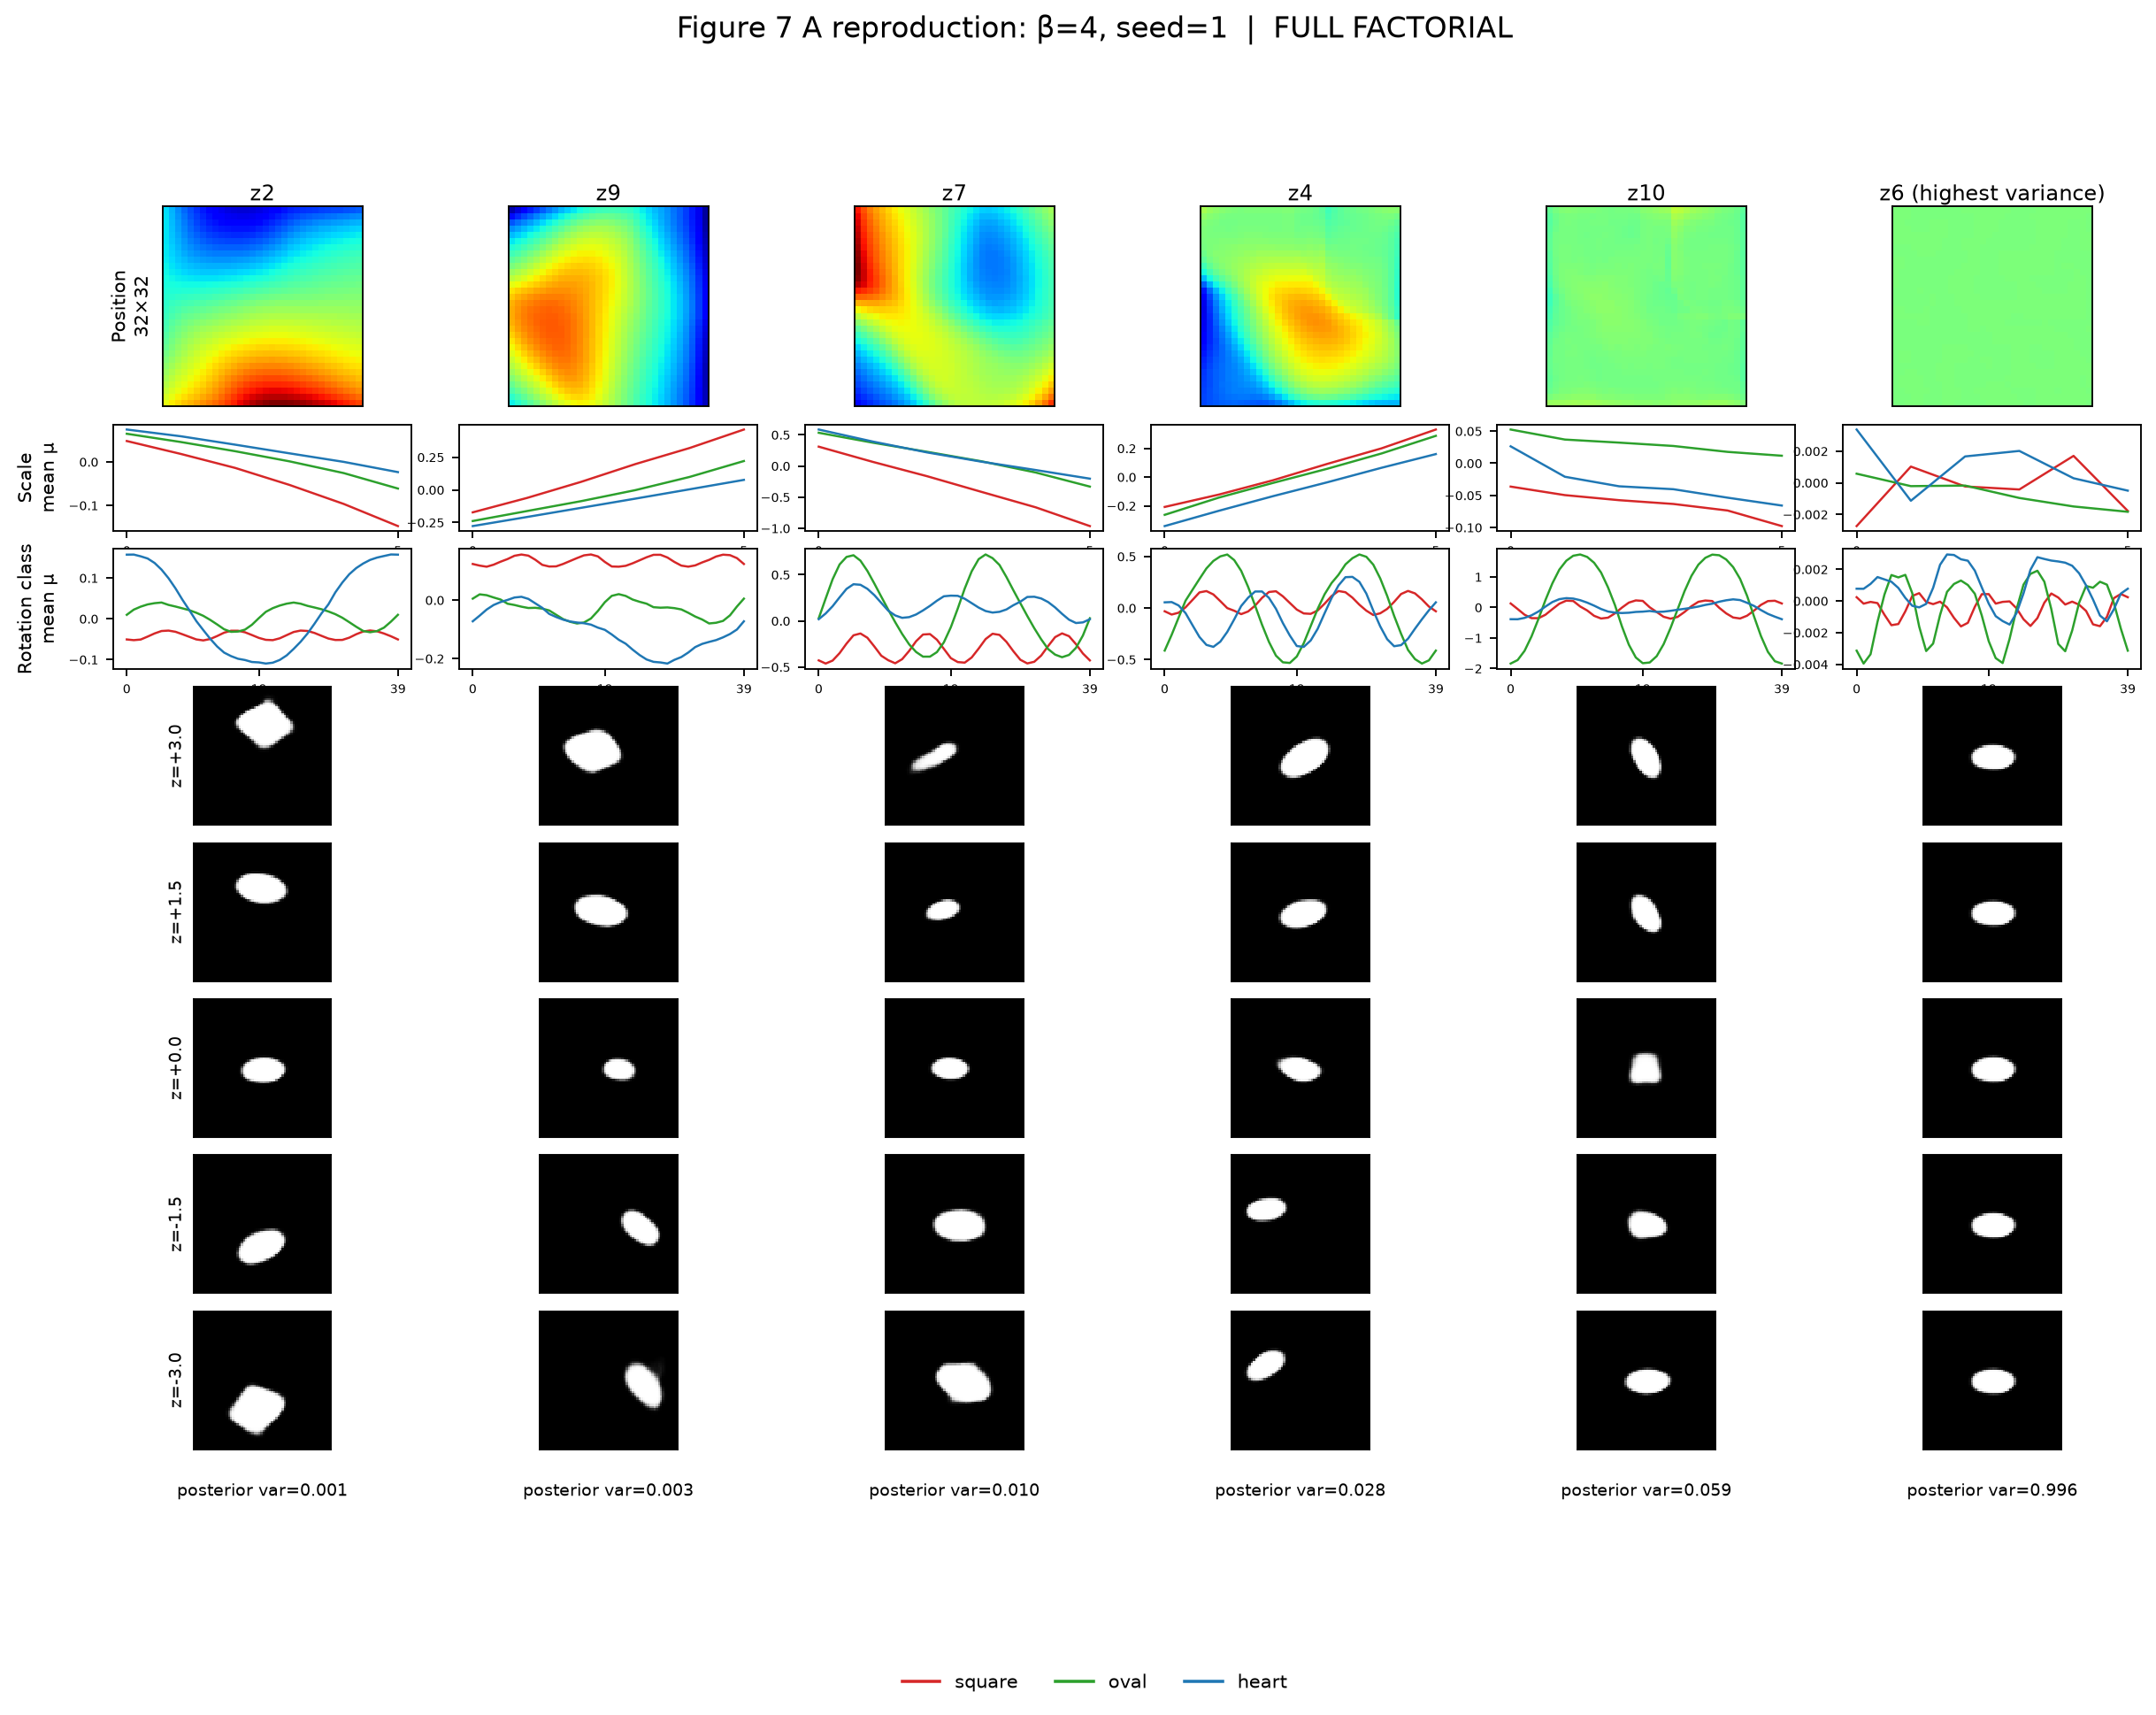

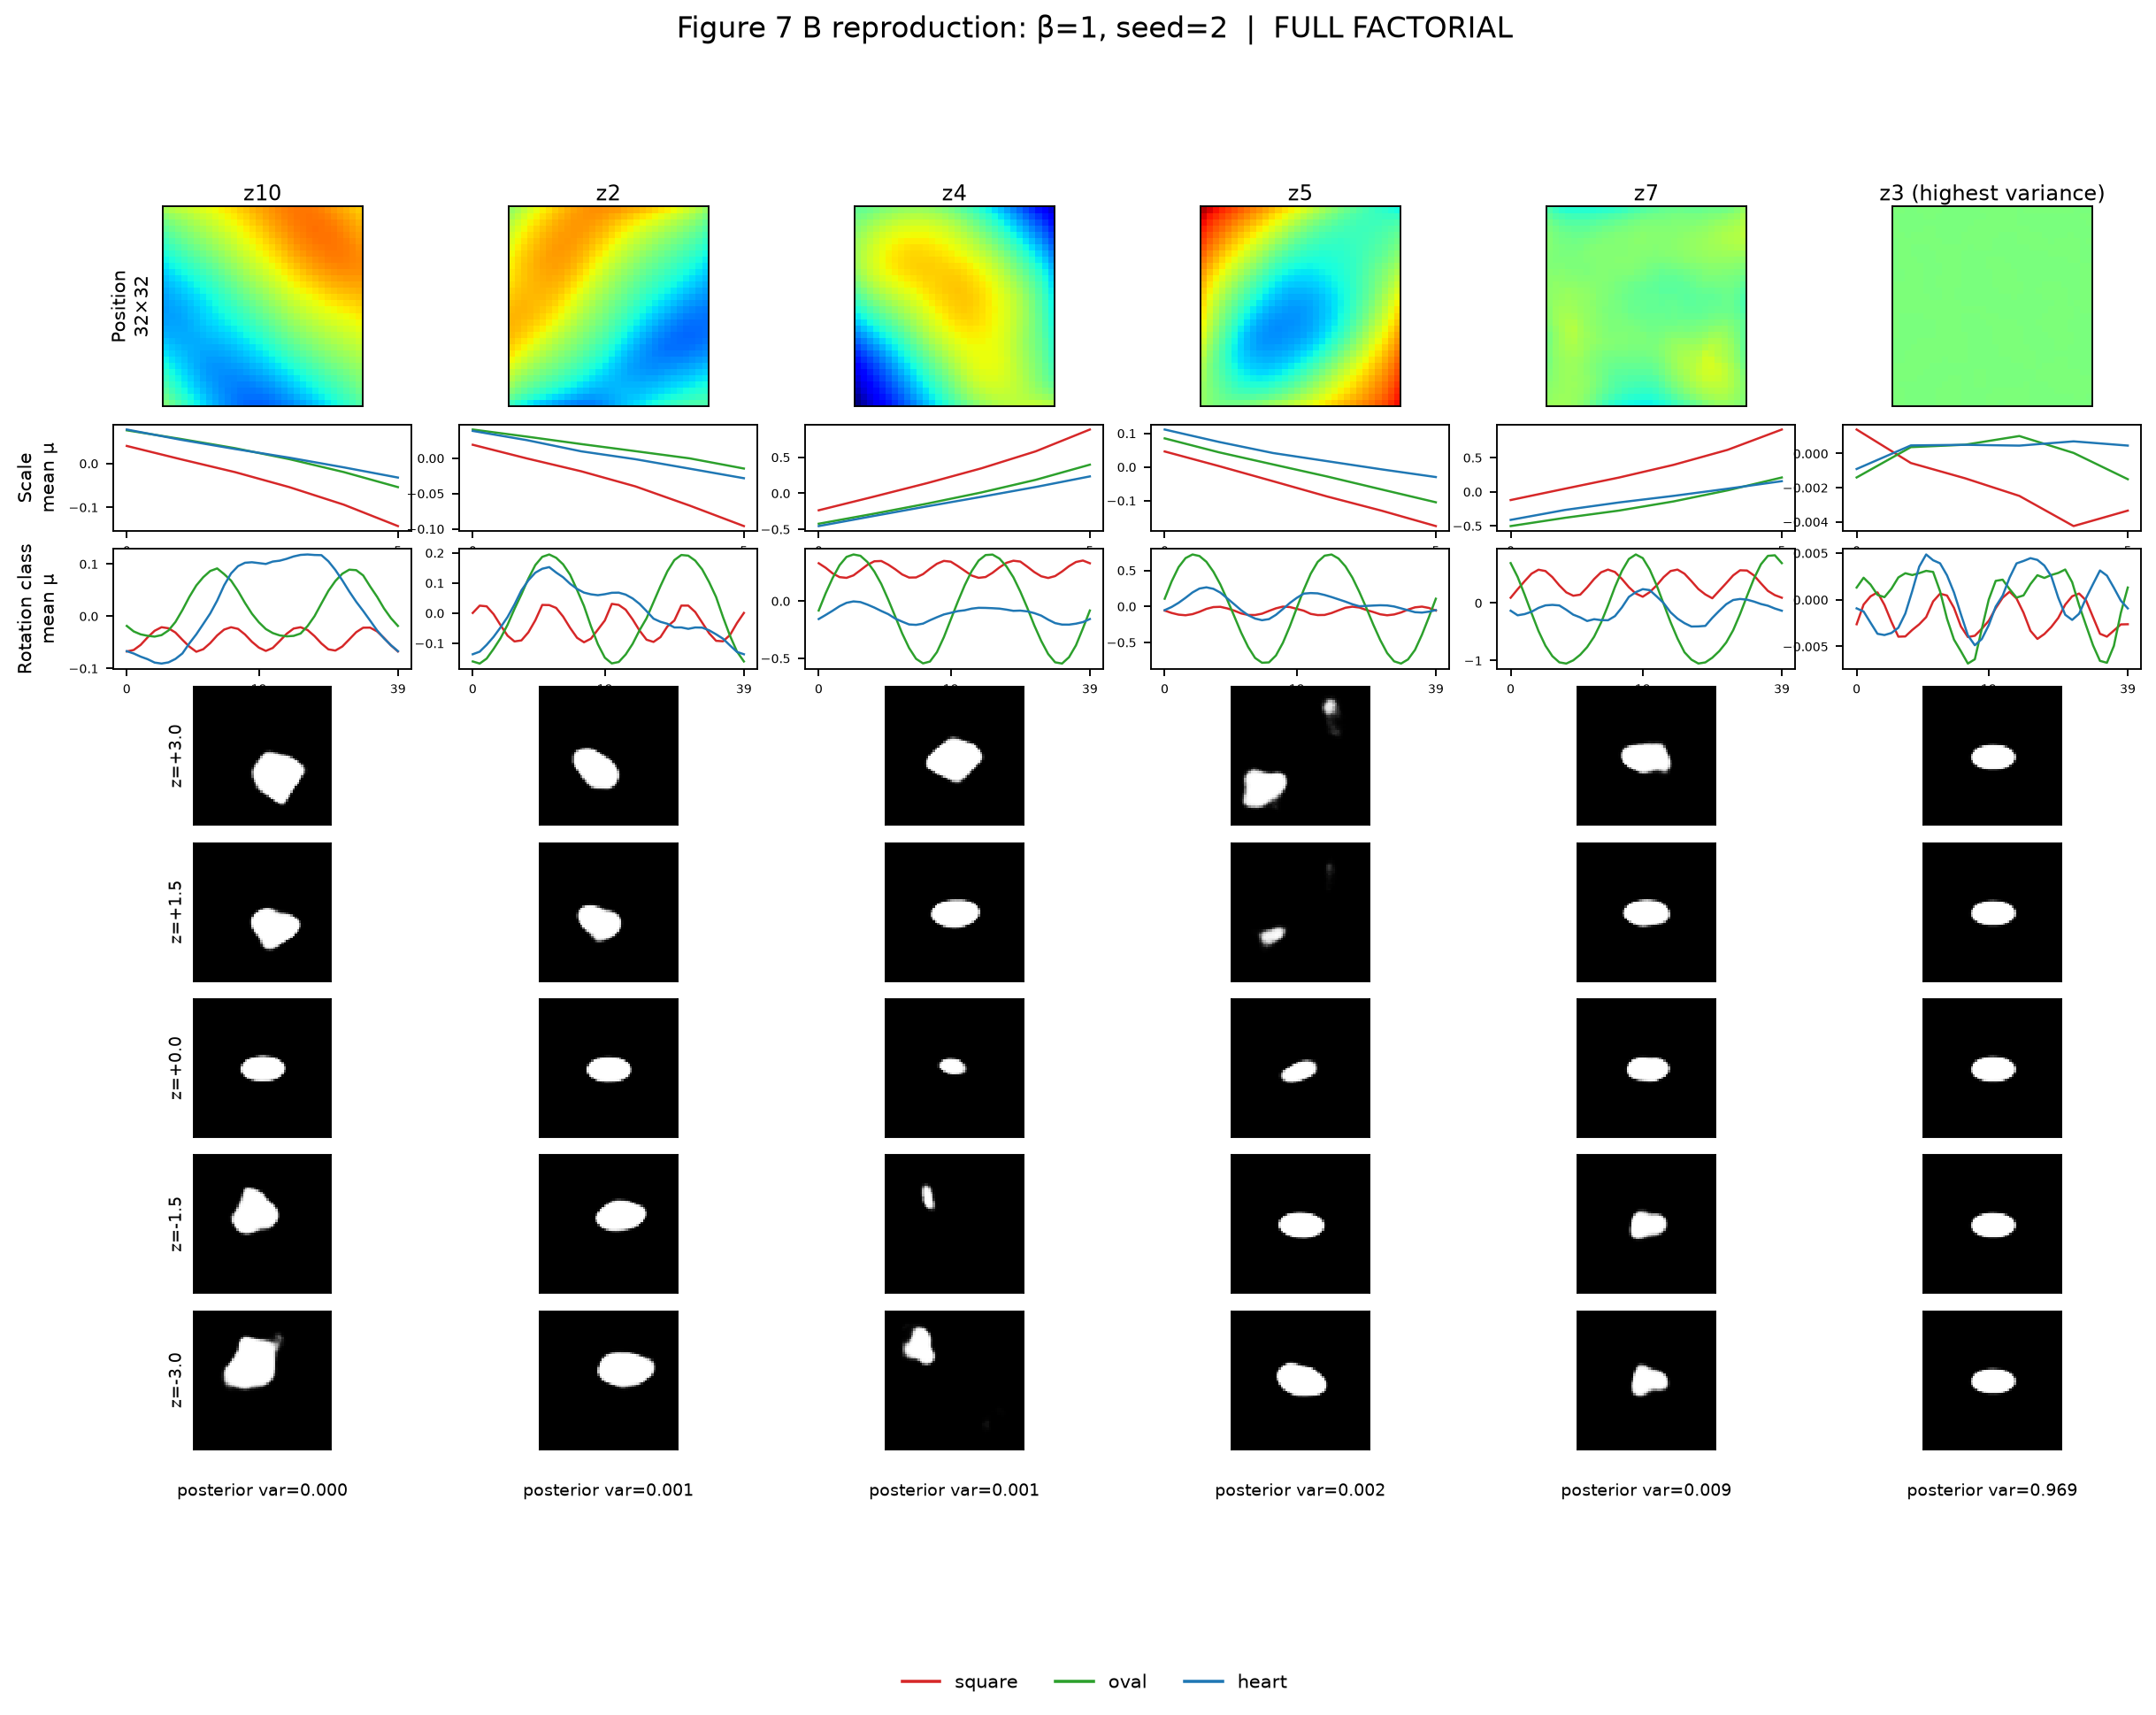

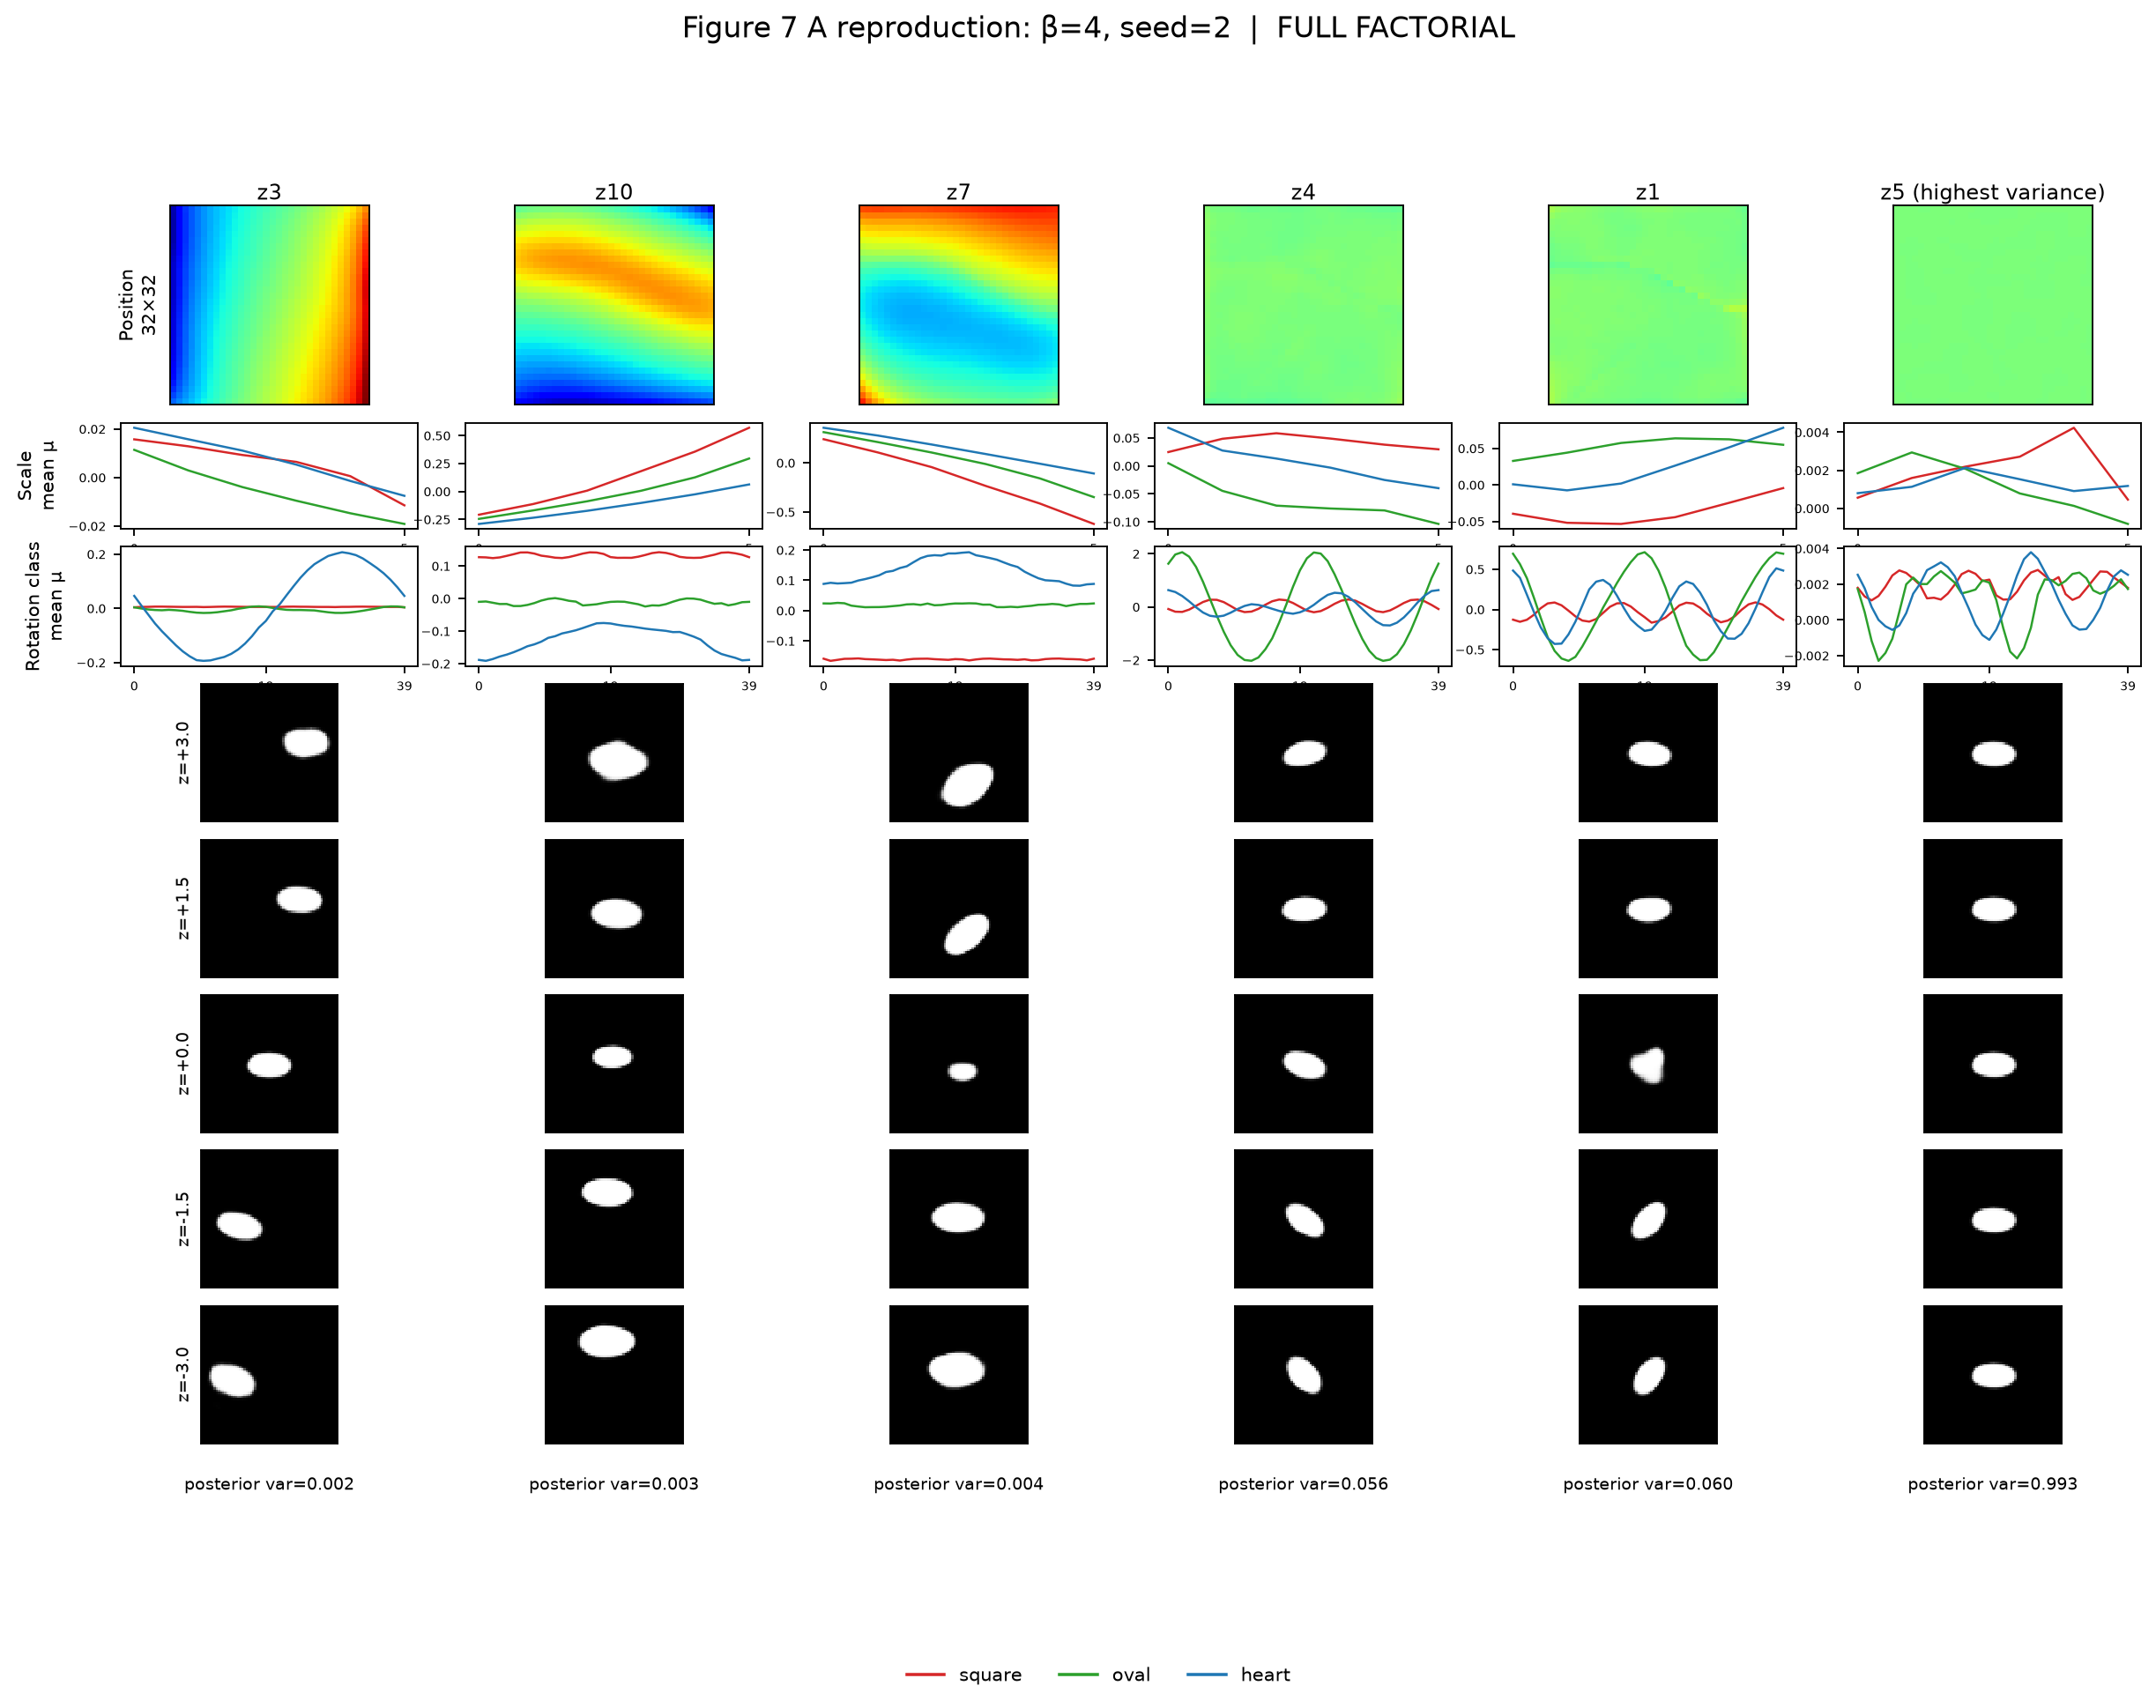

Measured final training epochs:


,beta,seed,epoch,optimizer_step,examples,total,reconstruction,kl,elapsed_seconds,mode,version
0,1.0,0,100,576000,737280,48.899140,29.304709,19.594431,2050.476136,full,paper3_fig7_v2
1,4.0,0,100,576000,737280,102.297180,51.855675,12.610376,2035.695443,full,paper3_fig7_v2
2,1.0,1,100,576000,737280,48.412961,30.601150,17.811811,2037.268151,full,paper3_fig7_v2
3,4.0,1,100,576000,737280,100.787425,49.812220,12.743801,2041.518208,full,paper3_fig7_v2
4,1.0,2,100,576000,737280,48.950447,29.434895,19.515552,2043.916881,full,paper3_fig7_v2
5,4.0,2,100,576000,737280,98.304812,47.601028,12.675946,2050.002885,full,paper3_fig7_v2


Measured latent statistics (all seeds and coordinates):


,original_latent_index_1based,posterior_variance,posterior_kl,posterior_mean,variance_rank_1based,beta,seed
0,1,0.970582,0.000949,-0.000989,8,1.0,0
1,2,0.966750,0.000992,-0.000217,7,1.0,0
2,3,0.976689,0.000674,0.001274,10,1.0,0
3,4,0.001612,3.354333,-0.026153,3,1.0,0
4,5,0.975474,0.000666,0.003160,9,1.0,0
5,6,0.000716,3.897111,-0.011922,2,1.0,0
6,7,0.001989,3.286267,-0.006361,4,1.0,0
7,8,0.012550,2.333610,-0.004750,6,1.0,0
8,9,0.000443,4.046632,0.006617,1,1.0,0
9,10,0.005963,2.681154,0.003035,5,1.0,0


In [8]:
# 8. Inference and figure generation; explicitly gated
if RUN_ANALYSIS:
    assert Path(CFG.dataset_npz).is_file(), "Set DSPRITES_NPZ before analysis"
    _ds, _factors, _keys = make_data()
    _figure_files = {}
    analysis_seeds = selected_seeds() if CFG.analyze_all_seeds else (CFG.display_seed,)
    for _seed in analysis_seeds:
        for _beta in CFG.betas:
            _model, _checkpoint = load_run_model(_beta, _seed)
            _analysis_dir = analyze_model(_model, _ds, _factors, _keys, _beta, _seed)
            _figure_files[(_beta, _seed)] = plot_factor_panel(_model, _beta, _seed)
            plot_factor_panel(_model, _beta, _seed, all_latents=True)
            plot_shape_diagnostic(_beta, _seed)
            del _model, _checkpoint
            if torch.cuda.is_available(): torch.cuda.empty_cache()
    if (1.0, CFG.display_seed) in _figure_files and (4.0, CFG.display_seed) in _figure_files:
        join_panels(_figure_files[(1.0, CFG.display_seed)],
                    _figure_files[(4.0, CFG.display_seed)],
                    OUT / f"Figure7AB_comparison_seed{CFG.display_seed}.png")
    # Native notebook image outputs, emitted by this executed cell.
    from IPython.display import display, Image as NotebookImage
    for _seed in analysis_seeds:
        if (1.0, _seed) in _figure_files and (4.0, _seed) in _figure_files:
            if _seed == CFG.display_seed:
                display(NotebookImage(filename=str(OUT / f"Figure7AB_comparison_seed{_seed}.png")))
            else:
                for _beta in CFG.betas:
                    display(NotebookImage(filename=str(_figure_files[(_beta, _seed)])))
    _history_tables = []
    _latent_tables = []
    for _seed in analysis_seeds:
        for _beta in CFG.betas:
            _rd = run_dir(_beta, _seed)
            _history_tables.append(pd.read_csv(_rd / "history.csv"))
            _latent_tables.append(pd.read_csv(_rd / "analysis" / "latent_summary.csv"))
    print("Measured final training epochs:")
    display(pd.concat([h.tail(1) for h in _history_tables], ignore_index=True))
    print("Measured latent statistics (all seeds and coordinates):")
    with pd.option_context("display.max_rows", None):
        display(pd.concat(_latent_tables, ignore_index=True))
    del _ds, _factors, _keys
else:
    print("ANALYSIS SKIPPED: set BETA_VAE_ANALYZE=1 after training checkpoints exist.")

## 9. Checks that require no dataset, download, or training

These checks verify that β changes **only** the coefficient of the KL term; the 10-dimensional model and reconstructed image shapes agree with the paper; a frozen 9/10-dimensional latent vector is unchanged during traversal; and factorial index arithmetic is consistent. **They are not a smoke training run and do not establish reproducibility of Figure 7.**

In [9]:
# 9. Lightweight default validation
assert N_FULL == 737_280 and math.prod(FACTOR_SIZES) == 737_280
assert list(TRAVERSAL_VALUES) == [3.0, 1.5, 0.0, -1.5, -3.0]
seed_everything(0)
_test_model = BetaVAE().cpu().eval()
with torch.no_grad():
    test_x = torch.randint(0, 2, (2, 1, 64, 64)).float()
    test_logits, test_mu, test_lv = _test_model(test_x)
    t1, rec1, kl1 = vae_loss(test_logits, test_x, test_mu, test_lv, 1)
    t4, rec4, kl4 = vae_loss(test_logits, test_x, test_mu, test_lv, 4)
    assert torch.allclose(t4 - t1, 3 * kl1, rtol=1e-4, atol=1e-3)
    assert torch.allclose(rec1, rec4) and torch.allclose(kl1, kl4)
    assert test_mu.shape == (2, 10)
    anchor = np.zeros(10, dtype=np.float32)
    anchor[1] = 0.2
    anchor[2] = -1.3
    z = torch.from_numpy(anchor).repeat(5, 1)
    z[:, 0] = torch.tensor(TRAVERSAL_VALUES, dtype=torch.float32)
    assert torch.allclose(z[:, 1:], torch.from_numpy(anchor[1:]).expand(5, -1))
    decoded = _test_model.decode_logits(z)
    assert decoded.shape == (5, 1, 64, 64)
ref_key = np.ravel_multi_index(CFG.anchor_factors, FACTOR_SIZES)
assert 0 <= ref_key < N_FULL
print("DEFAULT SANITY CHECKS PASSED (no dSprites access; no training).")
print("Training enabled?", RUN_TRAINING, "; analysis enabled?", RUN_ANALYSIS)
del _test_model, test_x, test_logits, test_mu, test_lv, t1, t4, rec1, rec4, kl1, kl4, z, decoded

DEFAULT SANITY CHECKS PASSED (no dSprites access; no training).
Training enabled? True ; analysis enabled? True


## 10. Running on a Slurm GPU node (after inspecting the code)

**Prerequisites:** Python with PyTorch, NumPy, pandas, matplotlib, Pillow, Jupyter and ipykernel. Provide the local dSprites `.npz` file (images + factor classes). No connection or installation is attempted by this notebook. Use a GPU allocation and writable scratch/output directory. For example, inside an existing Slurm GPU allocation:

```bash
export DSPRITES_NPZ=/path/to/dsprites_dataset.npz
export BETA_VAE_OUTPUT_ROOT=/path/to/scratch/paper3_fig7

# Inspect first, with both execution gates OFF (no data load, no training):
jupyter nbconvert --execute --ExecutePreprocessor.timeout=-1 --to notebook \
  --output paper3_inspection.ipynb paper3_figure7_beta_vae.ipynb

# TWO-EPOCH SMOKE RUN, ONE SEED PER BETA, 4096 EXAMPLES TOTAL:
BETA_VAE_MODE=smoke BETA_VAE_TRAIN=1 BETA_VAE_ANALYZE=1 \
  jupyter nbconvert --execute --ExecutePreprocessor.timeout=-1 --to notebook \
  --output paper3_smoke_executed.ipynb paper3_figure7_beta_vae.ipynb

# FULL REPRODUCTION, default 100 epochs × 3 seeds per β; can be expensive:
BETA_VAE_MODE=full BETA_VAE_TRAIN=1 BETA_VAE_ANALYZE=0 \
  jupyter nbconvert --execute --ExecutePreprocessor.timeout=-1 --to notebook \
  --output paper3_full_train_executed.ipynb paper3_figure7_beta_vae.ipynb

# Generate empirical full-factorial responses + all actual plots from final checkpoints:
BETA_VAE_MODE=full BETA_VAE_TRAIN=0 BETA_VAE_ANALYZE=1 \
  jupyter nbconvert --execute --ExecutePreprocessor.timeout=-1 --to notebook \
  --output paper3_full_analysis_executed.ipynb paper3_figure7_beta_vae.ipynb
```

If using an interactive Jupyter session instead, set `RUN_TRAINING=True` / `RUN_ANALYSIS=True` *in the configuration cell*. Because `Config` is immutable, switch modes with `CFG = replace(CFG, mode="full")` (or `"smoke"`), then update `OUT = Path(CFG.output_root) / CFG.mode` before executing the training/analysis cells. **Full and smoke checkpoints are incompatible and live in separate directories.**

### Review checklist before full training

1. Confirm `.npz` keys/dimensions and class-ID meanings, including `shape` order, by inspecting your downloaded local dataset. Stop rather than fabricate ground-truth factor indexes if the schema differs.
2. Confirm full data loss uses per-sample **sum over pixels**, not mean over pixels, and latent KL uses sum over all 10 coordinates.
3. Review the decoder Tanh convention and the fact that original epoch count, batch size and seed count were unspecified.
4. Inspect the two smoke checkpoints and their loss CSVs for finite values. Inspect the figure generated from **partial** smoke-factor averages only as a pipeline check.
5. Allocate enough storage: the packed image cache is ~378 MB; each optimizer checkpoint contains a large fully connected model and Adagrad state. Full 100-epoch × 6-run experiments require substantial GPU time.
6. In full mode inspect all seed outcomes. Do not equate one aesthetically convincing traversal with a statistically robust disentanglement result.

### What one seed can and cannot show

One seed demonstrates whether **one instance** of the β-VAE exhibits interpretable, mostly factor-specific traversals on the same data. It cannot establish that β=4 consistently disentangles better than β=1, nor that the precise latent indices reported in the paper will recur. The default three full seeds are an initial robustness check rather than replication of the paper's ten-run Figure 6 disentanglement-metric protocol.

**No author code, implementations or public reviews were consulted. Review corrections were checked against the supplied paper.**